In [98]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [99]:
def histplots(perf):
    # ------------------------------------------------------------------
    methods  = perf.index.get_level_values(0).unique()          # five methods
    metrics  = perf.columns[2:5]                                # the four columns
    n_rows   = len(metrics)
    n_cols   = len(methods)
    palette  = plt.cm.tab10.colors                              # 10 distinct colors
    figsize  = (4 * n_cols, 3 * n_rows)                         # scale as you like
    # ------------------------------------------------------------------
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize, squeeze=False)
    
    for row, metric in enumerate(metrics):
        # One common set of bin edges per *row* so bars line up across methods
        diffs_all = np.concatenate([
            (perf.loc[m, metric] - perf.loc[m, 'original']).values
            for m in methods
        ])
        bins = np.histogram_bin_edges(diffs_all, bins='auto')
    
        for col, (m, color) in enumerate(zip(methods, palette)):
            ax     = axes[row, col]
            delta  = perf.loc[m, metric] - perf.loc[m, 'original']
            ax.hist(delta, bins=bins, color=color, alpha=0.9, edgecolor='black')
    
            # Cosmetic touches
            ax.axvline(0, color='k', linestyle='--', linewidth=1)
            if row == 0:
                ax.set_title(m, fontsize=11)
            if col == 0:
                ax.set_ylabel(f'{metric}\nCount', fontsize=10)
            else:
                ax.set_ylabel('')
            ax.set_xlabel('Δ', fontsize=9)
    
    plt.tight_layout()
    plt.savefig('histograms_perf.png', dpi=300)
    plt.show()

In [100]:
def get_df(res, with_std=True):
    perf = {}
    perf_mi = {}
    for method in ['vanilla', 'justZ', 'irae1', 'irae2', 'irae3']:
        mname = method
        perf[mname] = pd.DataFrame(np.array([r[method][0][2:] - r[method][0][1] for r in res]),
                                   columns=['reconstructed $\\Delta$', 'intervened(0.2) $\\Delta$', 'intervened(1.0) $\\Delta$'])
    perf = pd.concat(perf)
    perf.index.set_names(['method', 'run'], inplace=True)

    if with_std:
        perf_mean = perf.groupby('method').agg(['mean', 'std'])
    else:
        perf_mean = perf.groupby('method').agg(['mean'])

    return perf_mean

In [101]:
import numpy as np
import os
import pandas as pd

def get_df(res, with_std: bool = True) -> pd.DataFrame:
    """
    Build a summary DataFrame where each cell is:
        'mean (std)'   — both rounded to 2 dp.
    The method with the largest mean in every column is shown in bold.

    Parameters
    ----------
    res : list
        Experiment results (same structure as before).
    with_std : bool, default True
        Whether to append the standard deviation.
    bold_markup : str, default '**'
        Mark-up sequence put *before* and *after* the winning cell
        (use '\\textbf{' and '}' for LaTeX).

    Returns
    -------
    pd.DataFrame
        Index:  method
        Columns: reconstructed Δ, intervened(0.2) Δ, intervened(1.0) Δ
        Cells:  formatted strings, winner in bold.
    """
    methods = ['vanilla', 'justZ', 'irae1', 'irae2', 'irae3']
    cols = ['reconstructed',
            'intervened(0.2)',
            'intervened(1.0)']

    # ── gather all runs ───────────────────────────────────────────────
    frames = []
    for m in methods:
        if res is None:
            runs = np.array([[np.nan, np.nan, np.nan]])
        else:
            runs = np.array([r[m][0][2:] - r[m][0][1] for r in res])
        df = pd.DataFrame(runs, columns=cols)
        df['method'] = m
        frames.append(df)

    perf = pd.concat(frames, ignore_index=True).set_index('method')

    # ── compute mean / std ────────────────────────────────────────────
    stats = perf.groupby('method').agg(['mean', 'std']).round(2)

    # ── identify winners (largest mean) ───────────────────────────────
    winners = {}
    for c in cols:
        max_mean = stats[(c, 'mean')].max()
        winners[c] = stats.index[stats[(c, 'mean')] == max_mean]

    # ── assemble formatted DataFrame ─────────────────────────────────
    out = pd.DataFrame(index=methods, columns=cols)   # preserves row order

    for c in cols:
        mu = stats[(c, 'mean')].astype(str)
        if with_std:
            sigma = stats[(c, 'std')].astype(str)
            cell = mu + " (" + sigma + ")"
        else:
            cell = mu

        # apply bold to winner(s)
        mask = stats.index.isin(winners[c])
        cell.loc[mask] = "\\textbf{" + cell.loc[mask] + "}"

        out[c] = cell

    return out


In [102]:
performance_dir = 'performance_results'
def get_table_df(start, finish, dgp, archs, ldims, regweights, iregs, trparams, warmstarts):
    start = 0
    finish = 39
    
    df = {}
    for arch in archs:
        df[arch] = {}
        for latent_dim in ldims:
            df[arch][latent_dim] = {}
            for reg_weight in regweights:
                df[arch][latent_dim][reg_weight] = {}
                for indep_reg in iregs:
                    df[arch][latent_dim][reg_weight][indep_reg] = {}
                    for train_params in trparams:
                        epochs1, epochs2, ss, bs, pt = train_params
                        df[arch][latent_dim][reg_weight][indep_reg][train_params] = {}
                        for warm_start in warmstarts:
                            if ss > 0:
                                conf_str = f'config_{dgp}_{arch}_{latent_dim}_{reg_weight}_{indep_reg}_hsic_{epochs1}_{bs}_{pt}_{ss}_{warm_start}_{epochs2}'
                            else:                                
                                conf_str = f'config_{dgp}_{arch}_{latent_dim}_{reg_weight}_{indep_reg}_hsic_{epochs1}_{bs}_{pt}_{warm_start}_{epochs2}'
                            if os.path.exists(os.path.join(performance_dir, f"performance_results_{start}_{finish}_{conf_str}.jbl")):
                                res = joblib.load(os.path.join(performance_dir, f"performance_results_{start}_{finish}_{conf_str}.jbl"))
                                df[arch][latent_dim][reg_weight][indep_reg][train_params][warm_start] = get_df(res, with_std=True).T
                            else:
                                df[arch][latent_dim][reg_weight][indep_reg][train_params][warm_start] = get_df(None).T
                        df[arch][latent_dim][reg_weight][indep_reg][train_params] = pd.concat(df[arch][latent_dim][reg_weight][indep_reg][train_params])
                    df[arch][latent_dim][reg_weight][indep_reg] = pd.concat(df[arch][latent_dim][reg_weight][indep_reg])
                df[arch][latent_dim][reg_weight] = pd.concat(df[arch][latent_dim][reg_weight])
            df[arch][latent_dim] = pd.concat(df[arch][latent_dim])
        df[arch] = pd.concat(df[arch])
    df = pd.concat(df)
    df.index.set_names(['arch', 'ldim', 'wreg', 'ireg', 'epochs', 'epochs_ws', 's', 'bs', 'pt', 'ws', 'image'], inplace=True)

    return df

# Case 1 Tables

In [112]:
start = 0
finish = 39
dgp = 'dgp1'
archs = ['conv']
ldims = [10]
regweights = [10.0]
iregs = ['linear']
trparams = [(500, 300, 1000, 100, 10), (100, 50, 10000, 100, 10), (40, 20, 30000, 256, 5), (50, 50, -1, 256, 5)]
warmstarts = [True]
df = get_table_df(start, finish, dgp, archs, ldims, regweights, iregs, trparams, warmstarts)
df = df.reset_index(level='epochs_ws', drop=True)
df = df.reset_index(level='wreg', drop=True)
df = df.reset_index(level='epochs', drop=True)
display(df)

vanilla  \
arch ldim ireg   s      bs  pt ws   image                                    
conv 10   linear  1000  100 10 True reconstructed    \textbf{-0.57 (0.03)}   
                                    intervened(0.2)           -0.56 (0.04)   
                                    intervened(1.0)           -0.51 (0.05)   
                  10000 100 10 True reconstructed             -0.51 (0.03)   
                                    intervened(0.2)            -0.5 (0.03)   
                                    intervened(1.0)           -0.47 (0.04)   
                  30000 256 5  True reconstructed             -0.51 (0.03)   
                                    intervened(0.2)           -0.49 (0.03)   
                                    intervened(1.0)           -0.44 (0.05)   
                 -1     256 5  True reconstructed             -0.47 (0.02)   
                                    intervened(0.2)           -0.46 (0.03)   
                                    intervened(1.0)           -0.41 (0.06)   

                                                                     justZ  \
arch ldim ireg   s      bs  pt ws   image                                    
conv 10   linear  1000  100 10 True reconstructed             -0.64 (0.17)   
                                    intervened(0.2)  \textbf{-0.44 (0.14)}   
                                    intervened(1.0)           -0.39 (0.15)   
                  10000 100 10 True reconstructed             -0.73 (0.04)   
                                    intervened(0.2)           -0.07 (0.15)   
                                    intervened(1.0)             0.04 (0.2)   
                  30000 256 5  True reconstructed             -0.74 (0.04)   
                                    intervened(0.2)           -0.11 (0.08)   
                                    intervened(1.0)           -0.06 (0.12)   
                 -1     256 5  True reconstructed             -0.71 (0.05)   
                                    intervened(0.2)           -0.06 (0.26)   
                                    intervened(1.0)            0.05 (0.29)   

                                                            irae1  \
arch ldim ireg   s      bs  pt ws   image                           
conv 10   linear  1000  100 10 True reconstructed     -0.6 (0.15)   
                                    intervened(0.2)   -0.5 (0.14)   
                                    intervened(1.0)  -0.42 (0.15)   
                  10000 100 10 True reconstructed    -0.73 (0.04)   
                                    intervened(0.2)   0.07 (0.26)   
                                    intervened(1.0)   0.15 (0.29)   
                  30000 256 5  True reconstructed    -0.73 (0.04)   
                                    intervened(0.2)  -0.17 (0.11)   
                                    intervened(1.0)   -0.13 (0.2)   
                 -1     256 5  True reconstructed    -0.71 (0.04)   
                                    intervened(0.2)    0.14 (0.3)   
                                    intervened(1.0)   0.26 (0.36)   

                                                                     irae2  \
arch ldim ireg   s      bs  pt ws   image                                    
conv 10   linear  1000  100 10 True reconstructed             -0.63 (0.09)   
                                    intervened(0.2)           -0.52 (0.16)   
                                    intervened(1.0)            -0.34 (0.2)   
                  10000 100 10 True reconstructed    \textbf{-0.33 (0.05)}   
                                    intervened(0.2)            0.72 (0.48)   
                                    intervened(1.0)            0.92 (0.47)   
                  30000 256 5  True reconstructed    \textbf{-0.33 (0.05)}   
                                    intervened(0.2)    \textbf{0.38 (0.4)}   
                                    intervened(1.0)   \textbf{0.78 (0.43)}   
                 -1     256 5  True reconstructed    \te

In [104]:
df = df.reset_index(level=['arch', 'ireg', 'ldim', 'bs', 'pt', 'ws'], drop=True)
print(df.to_latex())

\begin{tabular}{lllllll}
\toprule
 &  & vanilla & justZ & irae1 & irae2 & irae3 \\
s & image &  &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{1000} & reconstructed & \textbf{-0.57 (0.03)} & -0.64 (0.17) & -0.6 (0.15) & -0.63 (0.09) & -0.62 (0.09) \\
 & intervened(0.2) & -0.56 (0.04) & \textbf{-0.44 (0.14)} & -0.5 (0.14) & -0.52 (0.16) & -0.46 (0.19) \\
 & intervened(1.0) & -0.51 (0.05) & -0.39 (0.15) & -0.42 (0.15) & -0.34 (0.2) & \textbf{-0.31 (0.24)} \\
\cline{1-7}
\multirow[t]{3}{*}{10000} & reconstructed & -0.51 (0.03) & -0.73 (0.04) & -0.73 (0.04) & \textbf{-0.33 (0.05)} & \textbf{-0.33 (0.04)} \\
 & intervened(0.2) & -0.5 (0.03) & -0.07 (0.15) & 0.07 (0.26) & 0.72 (0.48) & \textbf{0.87 (0.43)} \\
 & intervened(1.0) & -0.47 (0.04) & 0.04 (0.2) & 0.15 (0.29) & 0.92 (0.47) & \textbf{1.1 (0.46)} \\
\cline{1-7}
\multirow[t]{3}{*}{30000} & reconstructed & -0.51 (0.03) & -0.74 (0.04) & -0.73 (0.04) & \textbf{-0.33 (0.05)} & \textbf{-0.33 (0.06)} \\
 & intervened(0.2) & -0.49 (0.03) & -0.11

# Case 2 Tables

In [117]:
start = 0
finish = 39
dgp = 'dgp2'
archs = ['dense', 'conv']
ldims = [10, 32]
regweights = [1.0]
iregs = ['linear', 'pairwise']
trparams = [(50, 50, -1, 256, 5)]
warmstarts = [False, True]
df = get_table_df(start, finish, dgp, archs, ldims, regweights, iregs, trparams, warmstarts)
df = df.reset_index(level=['epochs_ws', 'wreg', 'epochs'], drop=True)
df = df.reset_index(level=['bs', 'pt', 's'], drop=True)
display(df)

vanilla                 justZ  \
arch  ldim ireg     ws    image                                                 
dense 10   linear   False reconstructed    -0.46 (0.02)          -0.67 (0.02)   
                          intervened(0.2)  -0.45 (0.02)   \textbf{1.4 (0.12)}   
                          intervened(1.0)  -0.37 (0.02)           1.54 (0.11)   
                    True  reconstructed    -0.46 (0.02)          -0.67 (0.02)   
                          intervened(0.2)  -0.45 (0.02)   \textbf{1.4 (0.12)}   
                          intervened(1.0)  -0.37 (0.02)  \textbf{1.54 (0.11)}   
           pairwise False reconstructed    -0.46 (0.02)          -0.67 (0.02)   
                          intervened(0.2)  -0.45 (0.02)   \textbf{1.4 (0.12)}   
                          intervened(1.0)  -0.37 (0.02)  \textbf{1.54 (0.11)}   
                    True  reconstructed    -0.46 (0.02)          -0.67 (0.02)   
                          intervened(0.2)  -0.45 (0.02)   \textbf{1.4 (0.12)}   
                          intervened(1.0)  -0.37 (0.02)  \textbf{1.54 (0.11)}   
      32   linear   False reconstructed    -0.46 (0.02)          -0.67 (0.02)   
                          intervened(0.2)  -0.45 (0.02)   \textbf{1.4 (0.12)}   
                          intervened(1.0)  -0.37 (0.02)  \textbf{1.54 (0.11)}   
                    True  reconstructed    -0.46 (0.02)          -0.67 (0.02)   
                          intervened(0.2)  -0.45 (0.02)   \textbf{1.4 (0.12)}   
                          intervened(1.0)  -0.37 (0.02)  \textbf{1.54 (0.11)}   
           pairwise False reconstructed    -0.46 (0.02)          -0.67 (0.02)   
                          intervened(0.2)  -0.45 (0.02)   \textbf{1.4 (0.12)}   
                          intervened(1.0)  -0.37 (0.02)  \textbf{1.54 (0.11)}   
                    True  reconstructed    -0.46 (0.02)          -0.67 (0.02)   
                          intervened(0.2)  -0.45 (0.02)   \textbf{1.4 (0.12)}   
                          intervened(1.0)  -0.37 (0.02)  \textbf{1.54 (0.11)}   
conv  10   linear   False reconstructed    -0.37 (0.02)           -0.6 (0.06)   
                          intervened(0.2)  -0.36 (0.03)           0.21 (0.34)   
                          intervened(1.0)  -0.31 (0.07)            0.4 (0.56)   
                    True  reconstructed    -0.37 (0.02)           -0.6 (0.06)   
                          intervened(0.2)  -0.36 (0.03)           0.21 (0.34)   
                          intervened(1.0)  -0.31 (0.07)            0.4 (0.56)   
           pairwise False reconstructed    -0.37 (0.02)           -0.6 (0.06)   
                          intervened(0.2)  -0.36 (0.03)           0.21 (0.34)   
                          intervened(1.0)  -0.31 (0.07)            0.4 (0.56)   
                    True  reconstructed    -0.37 (0.02)           -0.6 (0.06)   
                          intervened(0.2)  -0.36 (0.03)           0.21 (0.34)   
                          intervened(1.0)  -0.31 (0.07)            0.4 (0.56)   
      32   linear   False reconstructed    -0.37 (0.02)           -0.6 (0.06)   
                          intervened(0.2)  -0.36 (0.03)           0.21 (0.34)   
                          intervened(1.0)  -0.31 (0.07)            0.4 (0.56)   
                    True  reconstructed    -0.37 (0.02)           -0.6 (0.06)   
                          intervened(0.2)  -0.36 (0.03)           0.21 (0.34)   
                          intervened(1.0)  -0.31 (0.07)            0.4 (0.56)   
           pairwise False reconstructed    -0.37 (0.02)           -0.6 (0.06)   
                          intervened(0.2)  -0.36 (0.03)  \textbf{0.21 (0.34)}   
                          intervened(1.0)  -0.31 (0.07)   \textbf{0.4 (0.56)}   
                    True  reconstructed    -0.37 (0.02)           -0.6 (0.06)   
                          intervened(0.2)  -0.36 (0.03)           0.21 (0.34)   
                          intervened(1.0)  -0.31 (0.07)            0.4 (0.56)  

In [118]:
print(df.to_latex())

\begin{tabular}{llllllllll}
\toprule
 &  &  &  &  & vanilla & justZ & irae1 & irae2 & irae3 \\
arch & ldim & ireg & ws & image &  &  &  &  &  \\
\midrule
\multirow[t]{24}{*}{dense} & \multirow[t]{12}{*}{10} & \multirow[t]{6}{*}{linear} & \multirow[t]{3}{*}{False} & reconstructed & -0.46 (0.02) & -0.67 (0.02) & -0.67 (0.02) & \textbf{-0.27 (0.01)} & -0.28 (0.02) \\
 &  &  &  & intervened(0.2) & -0.45 (0.02) & \textbf{1.4 (0.12)} & \textbf{1.4 (0.1)} & 1.39 (0.15) & 1.39 (0.2) \\
 &  &  &  & intervened(1.0) & -0.37 (0.02) & 1.54 (0.11) & 1.54 (0.09) & \textbf{1.57 (0.12)} & 1.54 (0.18) \\
\cline{4-10}
 &  &  & \multirow[t]{3}{*}{True} & reconstructed & -0.46 (0.02) & -0.67 (0.02) & -0.67 (0.02) & \textbf{-0.36 (0.14)} & -0.39 (0.16) \\
 &  &  &  & intervened(0.2) & -0.45 (0.02) & \textbf{1.4 (0.12)} & \textbf{1.4 (0.1)} & 1.17 (0.53) & 1.12 (0.58) \\
 &  &  &  & intervened(1.0) & -0.37 (0.02) & \textbf{1.54 (0.11)} & \textbf{1.54 (0.09)} & 1.32 (0.5) & 1.18 (0.6) \\
\cline{3-10} \cline{4

# Case 3 Tables

In [131]:
start = 0
finish = 39
dgp = 'dgp3'
archs = ['dense', 'conv']
ldims = [10, 32]
regweights = [1.0]
iregs = ['linear']
trparams = [(50, 50, -1, 256, 5)]
warmstarts = [False]
df = get_table_df(start, finish, dgp, archs, ldims, regweights, iregs, trparams, warmstarts)
df = df.reset_index(level=['epochs_ws', 'wreg', 'epochs'], drop=True)
df = df.reset_index(level=['bs', 'pt', 's'], drop=True)
display(df)

vanilla                 justZ  \
arch  ldim ireg   ws    image                                                 
dense 10   linear False reconstructed    -0.46 (0.02)          -0.67 (0.02)   
                        intervened(0.2)  -0.45 (0.02)   \textbf{1.4 (0.12)}   
                        intervened(1.0)  -0.37 (0.03)           1.54 (0.11)   
      32   linear False reconstructed    -0.46 (0.02)          -0.67 (0.02)   
                        intervened(0.2)  -0.45 (0.02)   \textbf{1.4 (0.12)}   
                        intervened(1.0)  -0.37 (0.03)  \textbf{1.54 (0.11)}   
conv  10   linear False reconstructed    -0.37 (0.02)           -0.6 (0.06)   
                        intervened(0.2)  -0.36 (0.03)           0.21 (0.34)   
                        intervened(1.0)  -0.31 (0.07)            0.4 (0.56)   
      32   linear False reconstructed    -0.37 (0.02)           -0.6 (0.06)   
                        intervened(0.2)  -0.36 (0.03)           0.21 (0.34)   
                        intervened(1.0)  -0.31 (0.07)            0.4 (0.56)   

                                                        irae1  \
arch  ldim ireg   ws    image                                   
dense 10   linear False reconstructed            -0.67 (0.02)   
                        intervened(0.2)    \textbf{1.4 (0.1)}   
                        intervened(1.0)           1.54 (0.09)   
      32   linear False reconstructed            -0.67 (0.02)   
                        intervened(0.2)    \textbf{1.4 (0.1)}   
                        intervened(1.0)  \textbf{1.54 (0.09)}   
conv  10   linear False reconstructed             -0.6 (0.05)   
                        intervened(0.2)             0.4 (0.4)   
                        intervened(1.0)           0.69 (0.58)   
      32   linear False reconstructed             -0.6 (0.05)   
                        intervened(0.2)             0.4 (0.4)   
                        intervened(1.0)           0.69 (0.58)   

                                                         irae2  \
arch  ldim ireg   ws    image                                    
dense 10   linear False reconstructed    \textbf{-0.27 (0.01)}   
                        intervened(0.2)            1.38 (0.15)   
                        intervened(1.0)            1.57 (0.12)   
      32   linear False reconstructed    \textbf{-0.14 (0.02)}   
                        intervened(0.2)            0.74 (0.34)   
                        intervened(1.0)            1.42 (0.32)   
conv  10   linear False reconstructed    \textbf{-0.21 (0.03)}   
                        intervened(0.2)   \textbf{0.98 (0.23)}   
                        intervened(1.0)            1.25 (0.54)   
      32   linear False reconstructed     \textbf{-0.1 (0.03)}   
                        intervened(0.2)    \textbf{0.7 (0.33)}   
                        intervened(1.0)   \textbf{1.26 (0.39)}   

                                                         irae3  
arch  ldim ireg   ws    image                                   
dense 10   linear False reconstructed    \textbf{-0.27 (0.02)}  
                        intervened(0.2)            1.36 (0.15)  
                        intervened(1.0)   \textbf{1.58 (0.08)}  
      32   linear False reconstructed    \textbf{-0.14 (0.02)}  
                        intervened(0.2)            0.63 (0.35)  
                        intervened(1.0)            1.34 (0.39)  
conv  10   linear False reconstructed             -0.22 (0.03)  
                        intervened(0.2)            0.83 (0.41)  
                        intervened(1.0)   \textbf{1.28 (0.51)}  
      32   linear False reconstructed     \textbf{-0.1 (0.03)}  
                        intervened(0.2)            0.64 (0.38)  
                        intervened(1.0)            1.11 (0.42)

In [132]:
print(df.to_latex())

\begin{tabular}{llllllllll}
\toprule
 &  &  &  &  & vanilla & justZ & irae1 & irae2 & irae3 \\
arch & ldim & ireg & ws & image &  &  &  &  &  \\
\midrule
\multirow[t]{6}{*}{dense} & \multirow[t]{3}{*}{10} & \multirow[t]{3}{*}{linear} & \multirow[t]{3}{*}{False} & reconstructed & -0.46 (0.02) & -0.67 (0.02) & -0.67 (0.02) & \textbf{-0.27 (0.01)} & \textbf{-0.27 (0.02)} \\
 &  &  &  & intervened(0.2) & -0.45 (0.02) & \textbf{1.4 (0.12)} & \textbf{1.4 (0.1)} & 1.38 (0.15) & 1.36 (0.15) \\
 &  &  &  & intervened(1.0) & -0.37 (0.03) & 1.54 (0.11) & 1.54 (0.09) & 1.57 (0.12) & \textbf{1.58 (0.08)} \\
\cline{2-10} \cline{3-10} \cline{4-10}
 & \multirow[t]{3}{*}{32} & \multirow[t]{3}{*}{linear} & \multirow[t]{3}{*}{False} & reconstructed & -0.46 (0.02) & -0.67 (0.02) & -0.67 (0.02) & \textbf{-0.14 (0.02)} & \textbf{-0.14 (0.02)} \\
 &  &  &  & intervened(0.2) & -0.45 (0.02) & \textbf{1.4 (0.12)} & \textbf{1.4 (0.1)} & 0.74 (0.34) & 0.63 (0.35) \\
 &  &  &  & intervened(1.0) & -0.37 (0.03) & \t

# Case 4 Tables

In [133]:
start = 0
finish = 39
dgp = 'dgp4'
archs = ['dense', 'conv']
ldims = [10, 32]
regweights = [1.0]
iregs = ['linear']
trparams = [(50, 50, -1, 256, 5)]
warmstarts = [False]
df = get_table_df(start, finish, dgp, archs, ldims, regweights, iregs, trparams, warmstarts)
df = df.reset_index(level=['epochs_ws', 'wreg', 'epochs'], drop=True)
df = df.reset_index(level=['bs', 'pt', 's'], drop=True)
display(df)

vanilla                 justZ  \
arch  ldim ireg   ws    image                                                 
dense 10   linear False reconstructed    -0.16 (0.01)          -0.22 (0.01)   
                        intervened(0.2)  -0.15 (0.01)  \textbf{0.51 (0.03)}   
                        intervened(1.0)   -0.1 (0.02)  \textbf{0.55 (0.01)}   
      32   linear False reconstructed    -0.16 (0.01)          -0.22 (0.01)   
                        intervened(0.2)  -0.15 (0.01)  \textbf{0.51 (0.03)}   
                        intervened(1.0)   -0.1 (0.02)  \textbf{0.55 (0.01)}   
conv  10   linear False reconstructed    -0.13 (0.01)           -0.2 (0.02)   
                        intervened(0.2)  -0.13 (0.01)           0.26 (0.12)   
                        intervened(1.0)  -0.11 (0.04)           0.42 (0.19)   
      32   linear False reconstructed    -0.13 (0.01)           -0.2 (0.02)   
                        intervened(0.2)  -0.13 (0.01)           0.26 (0.12)   
                        intervened(1.0)  -0.11 (0.04)           0.42 (0.19)   

                                                        irae1  \
arch  ldim ireg   ws    image                                   
dense 10   linear False reconstructed            -0.22 (0.01)   
                        intervened(0.2)            0.5 (0.03)   
                        intervened(1.0)  \textbf{0.55 (0.02)}   
      32   linear False reconstructed            -0.22 (0.01)   
                        intervened(0.2)            0.5 (0.03)   
                        intervened(1.0)  \textbf{0.55 (0.02)}   
conv  10   linear False reconstructed             -0.2 (0.02)   
                        intervened(0.2)           0.28 (0.14)   
                        intervened(1.0)           0.44 (0.21)   
      32   linear False reconstructed             -0.2 (0.02)   
                        intervened(0.2)           0.28 (0.14)   
                        intervened(1.0)           0.44 (0.21)   

                                                         irae2  \
arch  ldim ireg   ws    image                                    
dense 10   linear False reconstructed    \textbf{-0.09 (0.01)}   
                        intervened(0.2)   \textbf{0.51 (0.02)}   
                        intervened(1.0)   \textbf{0.55 (0.01)}   
      32   linear False reconstructed    \textbf{-0.05 (0.01)}   
                        intervened(0.2)             0.5 (0.01)   
                        intervened(1.0)            0.54 (0.01)   
conv  10   linear False reconstructed    \textbf{-0.07 (0.03)}   
                        intervened(0.2)   \textbf{0.45 (0.03)}   
                        intervened(1.0)   \textbf{0.54 (0.01)}   
      32   linear False reconstructed    \textbf{-0.04 (0.03)}   
                        intervened(0.2)   \textbf{0.45 (0.04)}   
                        intervened(1.0)   \textbf{0.53 (0.01)}   

                                                         irae3  
arch  ldim ireg   ws    image                                   
dense 10   linear False reconstructed    \textbf{-0.09 (0.01)}  
                        intervened(0.2)   \textbf{0.51 (0.02)}  
                        intervened(1.0)   \textbf{0.55 (0.01)}  
      32   linear False reconstructed    \textbf{-0.05 (0.01)}  
                        intervened(0.2)            0.49 (0.03)  
                        intervened(1.0)            0.54 (0.01)  
conv  10   linear False reconstructed    \textbf{-0.07 (0.03)}  
                        intervened(0.2)            0.44 (0.05)  
                        intervened(1.0)            0.53 (0.02)  
      32   linear False reconstructed    \textbf{-0.04 (0.02)}  
                        intervened(0.2)   \textbf{0.45 (0.05)}  
                        intervened(1.0)            0.51 (0.08)

In [134]:
print(df.to_latex())

\begin{tabular}{llllllllll}
\toprule
 &  &  &  &  & vanilla & justZ & irae1 & irae2 & irae3 \\
arch & ldim & ireg & ws & image &  &  &  &  &  \\
\midrule
\multirow[t]{6}{*}{dense} & \multirow[t]{3}{*}{10} & \multirow[t]{3}{*}{linear} & \multirow[t]{3}{*}{False} & reconstructed & -0.16 (0.01) & -0.22 (0.01) & -0.22 (0.01) & \textbf{-0.09 (0.01)} & \textbf{-0.09 (0.01)} \\
 &  &  &  & intervened(0.2) & -0.15 (0.01) & \textbf{0.51 (0.03)} & 0.5 (0.03) & \textbf{0.51 (0.02)} & \textbf{0.51 (0.02)} \\
 &  &  &  & intervened(1.0) & -0.1 (0.02) & \textbf{0.55 (0.01)} & \textbf{0.55 (0.02)} & \textbf{0.55 (0.01)} & \textbf{0.55 (0.01)} \\
\cline{2-10} \cline{3-10} \cline{4-10}
 & \multirow[t]{3}{*}{32} & \multirow[t]{3}{*}{linear} & \multirow[t]{3}{*}{False} & reconstructed & -0.16 (0.01) & -0.22 (0.01) & -0.22 (0.01) & \textbf{-0.05 (0.01)} & \textbf{-0.05 (0.01)} \\
 &  &  &  & intervened(0.2) & -0.15 (0.01) & \textbf{0.51 (0.03)} & 0.5 (0.03) & 0.5 (0.01) & 0.49 (0.03) \\
 &  &  &  & interv

# Optional Histogram Plot Creations

In [14]:
def report(res, plot=True, with_std=True):
    perf = {}
    perf_mi = {}
    for method in ['vanilla', 'justZ', 'irae1', 'irae2', 'irae3']:
        mname = method
        perf[mname] = pd.DataFrame(np.array([r[method][0] for r in res]),
                                   columns=['true', 'original', 'recovered', 'intervened(0.2)', 'intervened(1.0)'])
        perf_mi[mname] = pd.DataFrame(np.array([r[method][1] for r in res]),
                                      columns=['true', 'original', 'recovered', 'intervened(0.2)', 'intervened(1.0)'])
    perf = pd.concat(perf)
    perf.index.set_names(['method', 'run'], inplace=True)
    perf_mi = pd.concat(perf_mi)
    perf_mi.index.set_names(['method', 'run'], inplace=True)

    if with_std:
        perf_mean = perf.groupby('method').agg(['mean', 'std'])
    else:
        perf_mean = perf.groupby('method').agg(['mean'])

    if plot:    
        display(perf_mean)        
        perf.groupby('method').mean().plot.bar()
        plt.show()
        histplots(perf)

    return perf_mean

In [15]:
def get_reports(start, finish, dgp, archs, ldims, regweights, iregs, trparams, warmstarts):
    start = 0
    finish = 39

    for arch in archs:
        for latent_dim in ldims:
            for reg_weight in regweights:
                for indep_reg in iregs:
                    for train_params in trparams:
                        epochs1, epochs2, ss, bs, pt = train_params
                        for warm_start in warmstarts:
                            if ss > 0:
                                conf_str = f'config_{dgp}_{arch}_{latent_dim}_{reg_weight}_{indep_reg}_hsic_{epochs1}_{bs}_{pt}_{ss}_{warm_start}_{epochs2}'
                            else:                                
                                conf_str = f'config_{dgp}_{arch}_{latent_dim}_{reg_weight}_{indep_reg}_hsic_{epochs1}_{bs}_{pt}_{warm_start}_{epochs2}'
                            print(conf_str)
                            if os.path.exists(os.path.join(performance_dir, f"performance_results_{start}_{finish}_{conf_str}.jbl")):
                                res = joblib.load(os.path.join(performance_dir, f"performance_results_{start}_{finish}_{conf_str}.jbl"))
                                report(res)
                            else:
                                print("Not found")

config_dgp2_dense_10_1.0_linear_hsic_50_256_5_False_50


true            original           recovered            \
             mean       std      mean       std      mean       std   
method                                                                
irae1    1.502673  0.002324  1.307258  0.002093  0.637556  0.018193   
irae2    1.502673  0.002324  1.307258  0.002093  1.032970  0.014430   
irae3    1.502673  0.002324  1.307258  0.002093  1.033296  0.016320   
justZ    1.502673  0.002324  1.307258  0.002093  0.637146  0.023963   
vanilla  1.502673  0.002324  1.307258  0.002093  0.843164  0.020536   

        intervened(0.2)           intervened(1.0)            
                   mean       std            mean       std  
method                                                       
irae1          2.704603  0.102484        2.846061  0.090137  
irae2          2.692433  0.149366        2.879312  0.118563  
irae3          2.658536  0.163958        2.888815  0.081168  
justZ          2.712072  0.117454        2.844415  0.113935  
vanilla        0.861240  0.017841        0.934845  0.025134

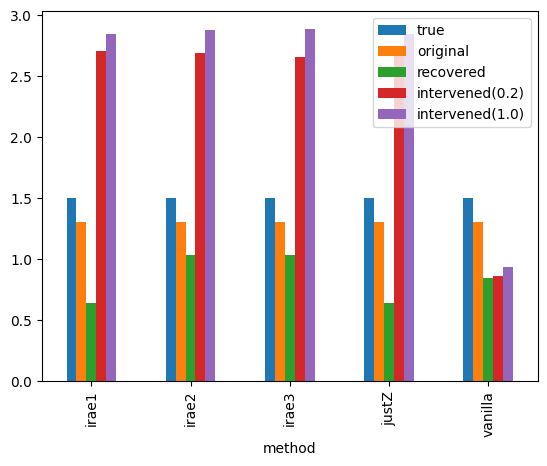

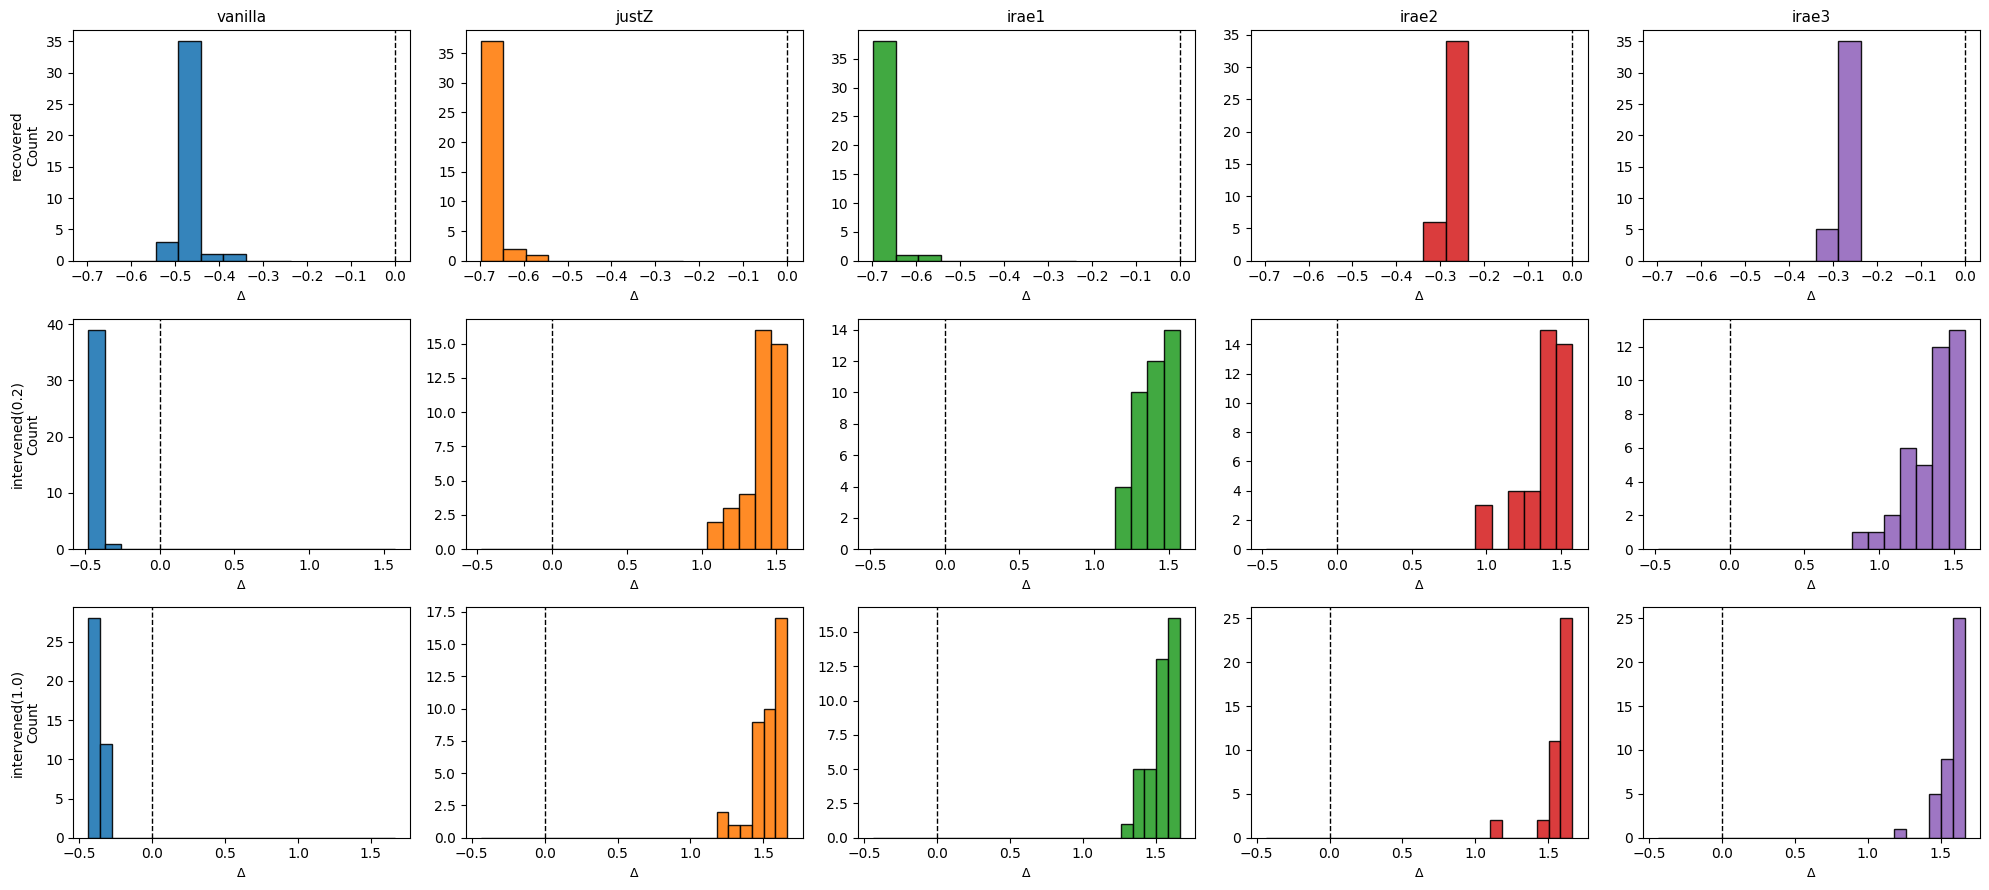

config_dgp2_dense_10_1.0_linear_hsic_50_256_5_True_50


true            original           recovered            \
             mean       std      mean       std      mean       std   
method                                                                
irae1    1.502673  0.002324  1.307258  0.002093  0.637556  0.018193   
irae2    1.502673  0.002324  1.307258  0.002093  0.947698  0.142689   
irae3    1.502673  0.002324  1.307258  0.002093  0.879987  0.199497   
justZ    1.502673  0.002324  1.307258  0.002093  0.637146  0.023963   
vanilla  1.502673  0.002324  1.307258  0.002093  0.843164  0.020536   

        intervened(0.2)           intervened(1.0)            
                   mean       std            mean       std  
method                                                       
irae1          2.704603  0.102484        2.846061  0.090137  
irae2          2.474170  0.526268        2.623879  0.496918  
irae3          2.228877  0.639250        2.395454  0.580369  
justZ          2.712072  0.117454        2.844415  0.113935  
vanilla        0.861240  0.017841        0.934845  0.025134

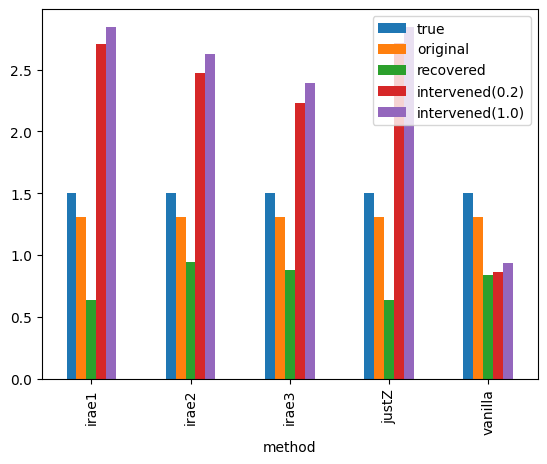

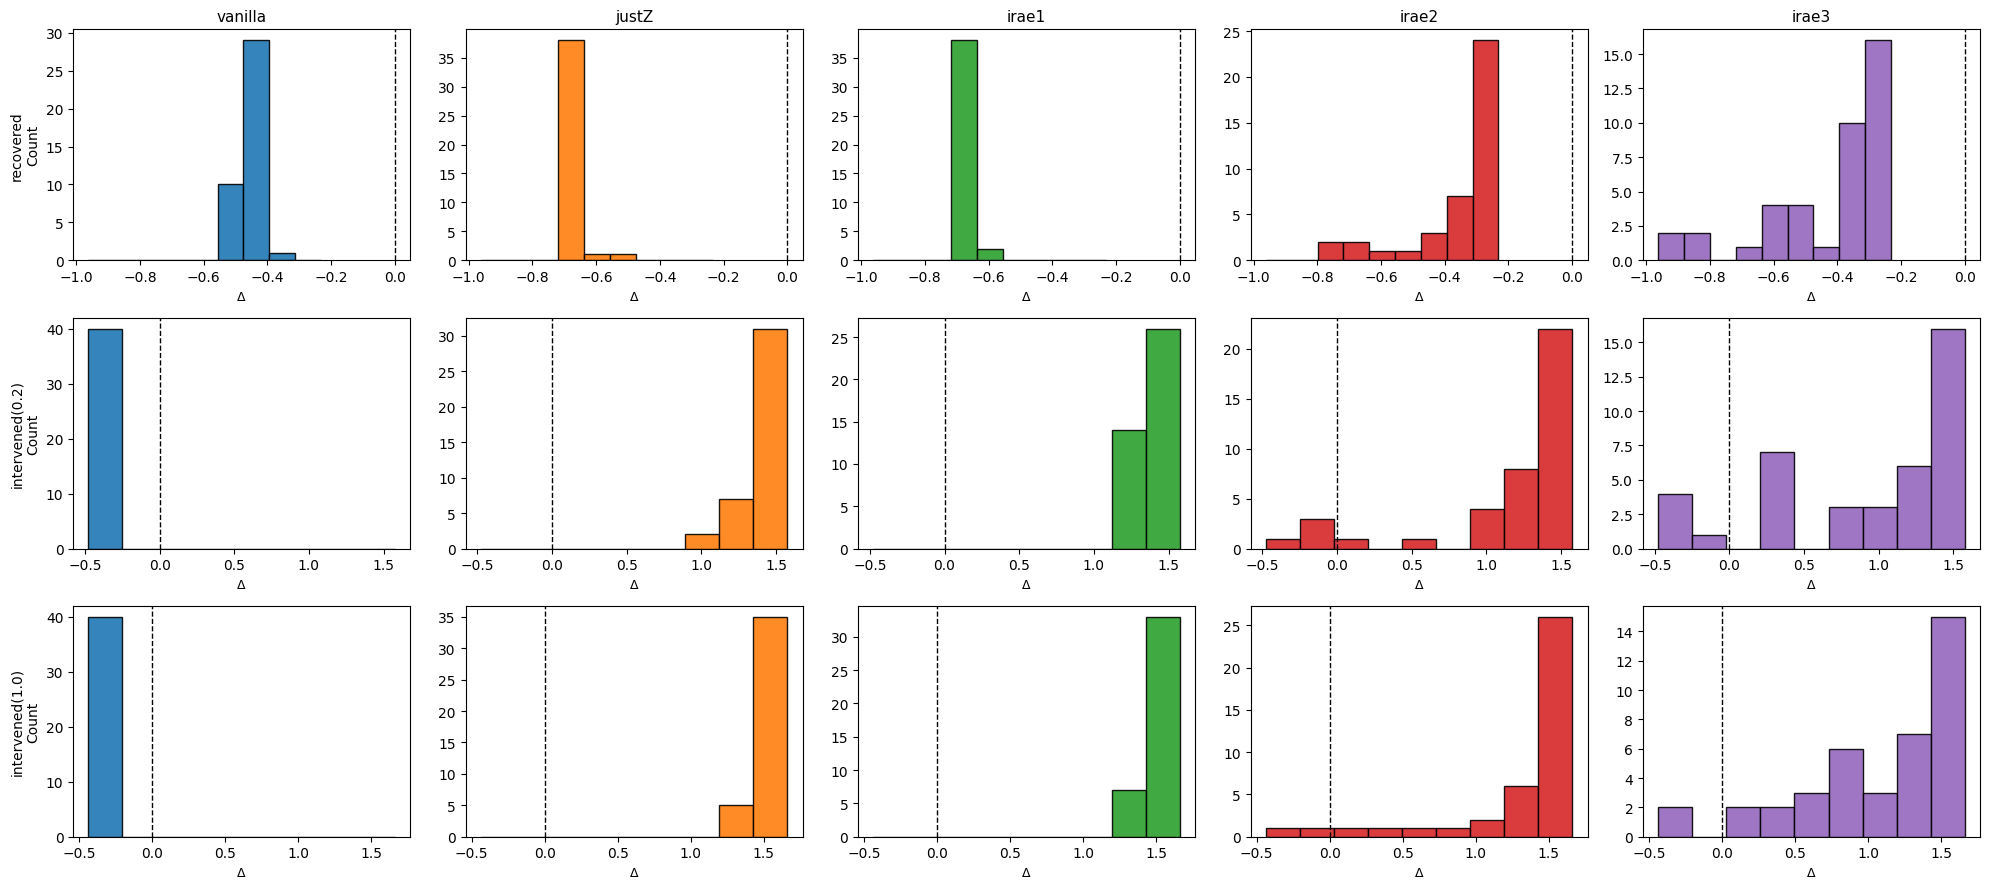

config_dgp2_dense_10_1.0_pairwise_hsic_50_256_5_False_50


true            original           recovered            \
             mean       std      mean       std      mean       std   
method                                                                
irae1    1.502673  0.002324  1.307258  0.002093  0.626096  0.014128   
irae2    1.502673  0.002324  1.307258  0.002093  1.011405  0.028826   
irae3    1.502673  0.002324  1.307258  0.002093  0.965033  0.024357   
justZ    1.502673  0.002324  1.307258  0.002093  0.637146  0.023963   
vanilla  1.502673  0.002324  1.307258  0.002093  0.843164  0.020536   

        intervened(0.2)           intervened(1.0)            
                   mean       std            mean       std  
method                                                       
irae1          2.709878  0.142581        2.840256  0.133995  
irae2          1.219115  0.372649        1.395969  0.570260  
irae3          1.481504  0.592594        1.767784  0.694909  
justZ          2.712072  0.117454        2.844415  0.113935  
vanilla        0.861240  0.017841        0.934845  0.025134

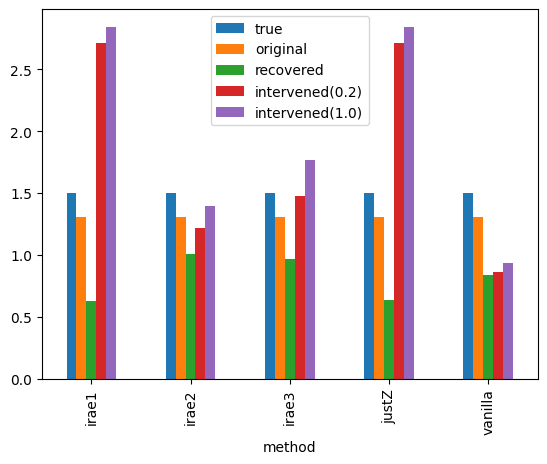

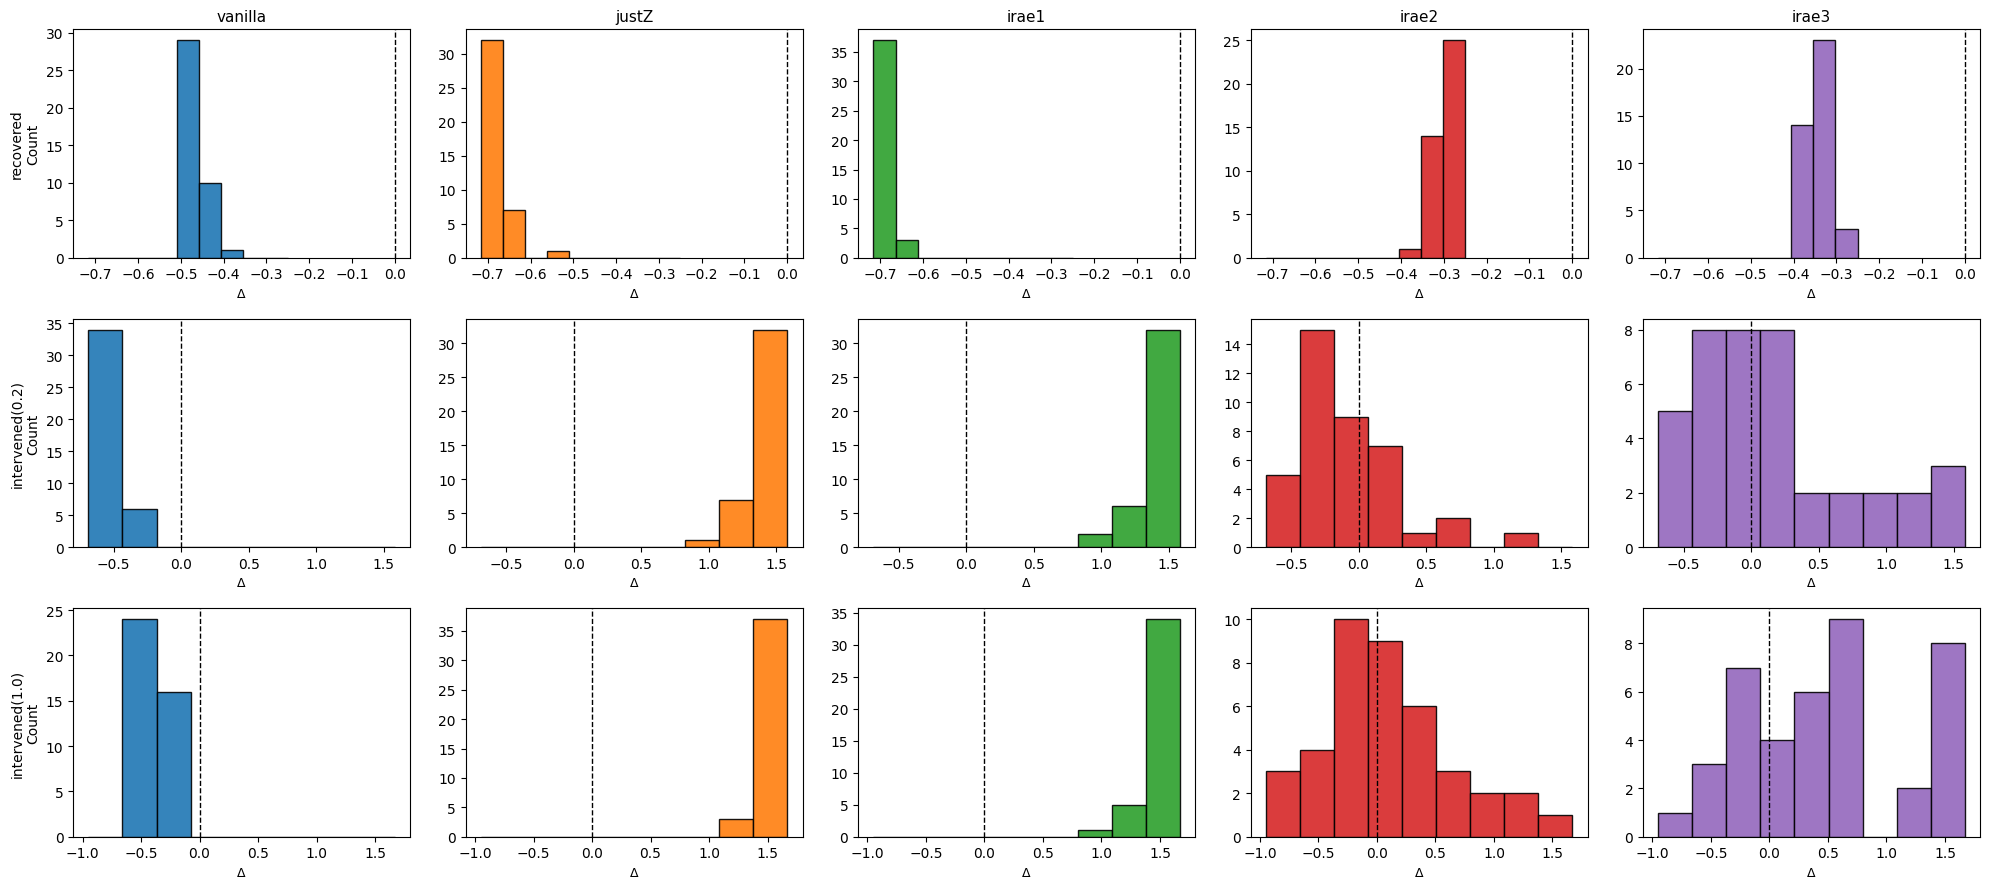

config_dgp2_dense_10_1.0_pairwise_hsic_50_256_5_True_50


true            original           recovered            \
             mean       std      mean       std      mean       std   
method                                                                
irae1    1.502673  0.002324  1.307258  0.002093  0.626096  0.014128   
irae2    1.502673  0.002324  1.307258  0.002093  0.972329  0.098442   
irae3    1.502673  0.002324  1.307258  0.002093  0.673055  0.252660   
justZ    1.502673  0.002324  1.307258  0.002093  0.637146  0.023963   
vanilla  1.502673  0.002324  1.307258  0.002093  0.843164  0.020536   

        intervened(0.2)           intervened(1.0)            
                   mean       std            mean       std  
method                                                       
irae1          2.709878  0.142581        2.840256  0.133995  
irae2          2.619903  0.240302        2.797692  0.154200  
irae3          1.906249  0.923158        2.163192  0.793171  
justZ          2.712072  0.117454        2.844415  0.113935  
vanilla        0.861240  0.017841        0.934845  0.025134

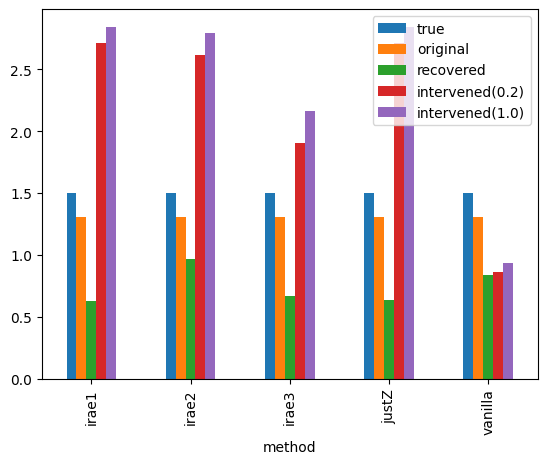

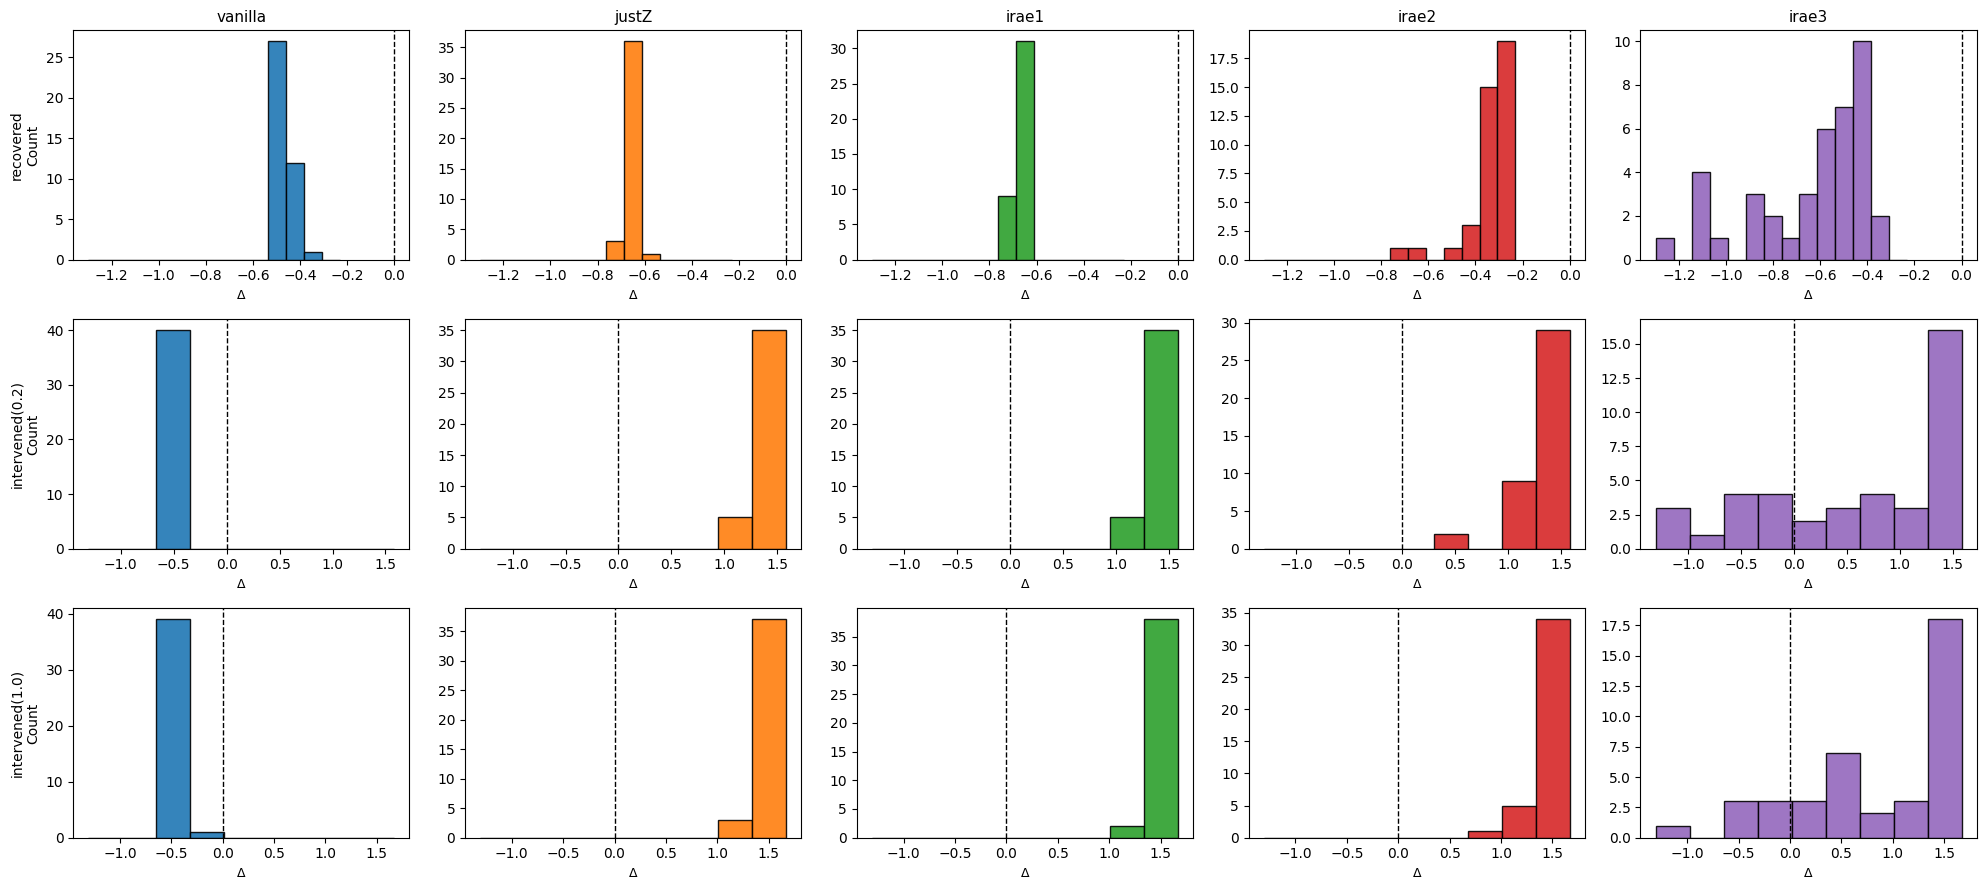

config_dgp2_dense_32_1.0_linear_hsic_50_256_5_False_50


true            original           recovered            \
             mean       std      mean       std      mean       std   
method                                                                
irae1    1.502673  0.002324  1.307258  0.002093  0.637556  0.018193   
irae2    1.502673  0.002324  1.307258  0.002093  1.163290  0.015912   
irae3    1.502673  0.002324  1.307258  0.002093  1.174931  0.014717   
justZ    1.502673  0.002324  1.307258  0.002093  0.637146  0.023963   
vanilla  1.502673  0.002324  1.307258  0.002093  0.843164  0.020536   

        intervened(0.2)           intervened(1.0)            
                   mean       std            mean       std  
method                                                       
irae1          2.704603  0.102484        2.846061  0.090137  
irae2          2.043445  0.341245        2.733463  0.316140  
irae3          1.932332  0.355689        2.645147  0.355571  
justZ          2.712072  0.117454        2.844415  0.113935  
vanilla        0.861240  0.017841        0.934845  0.025134

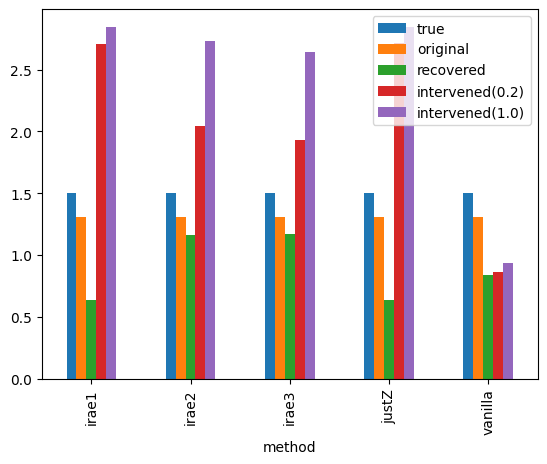

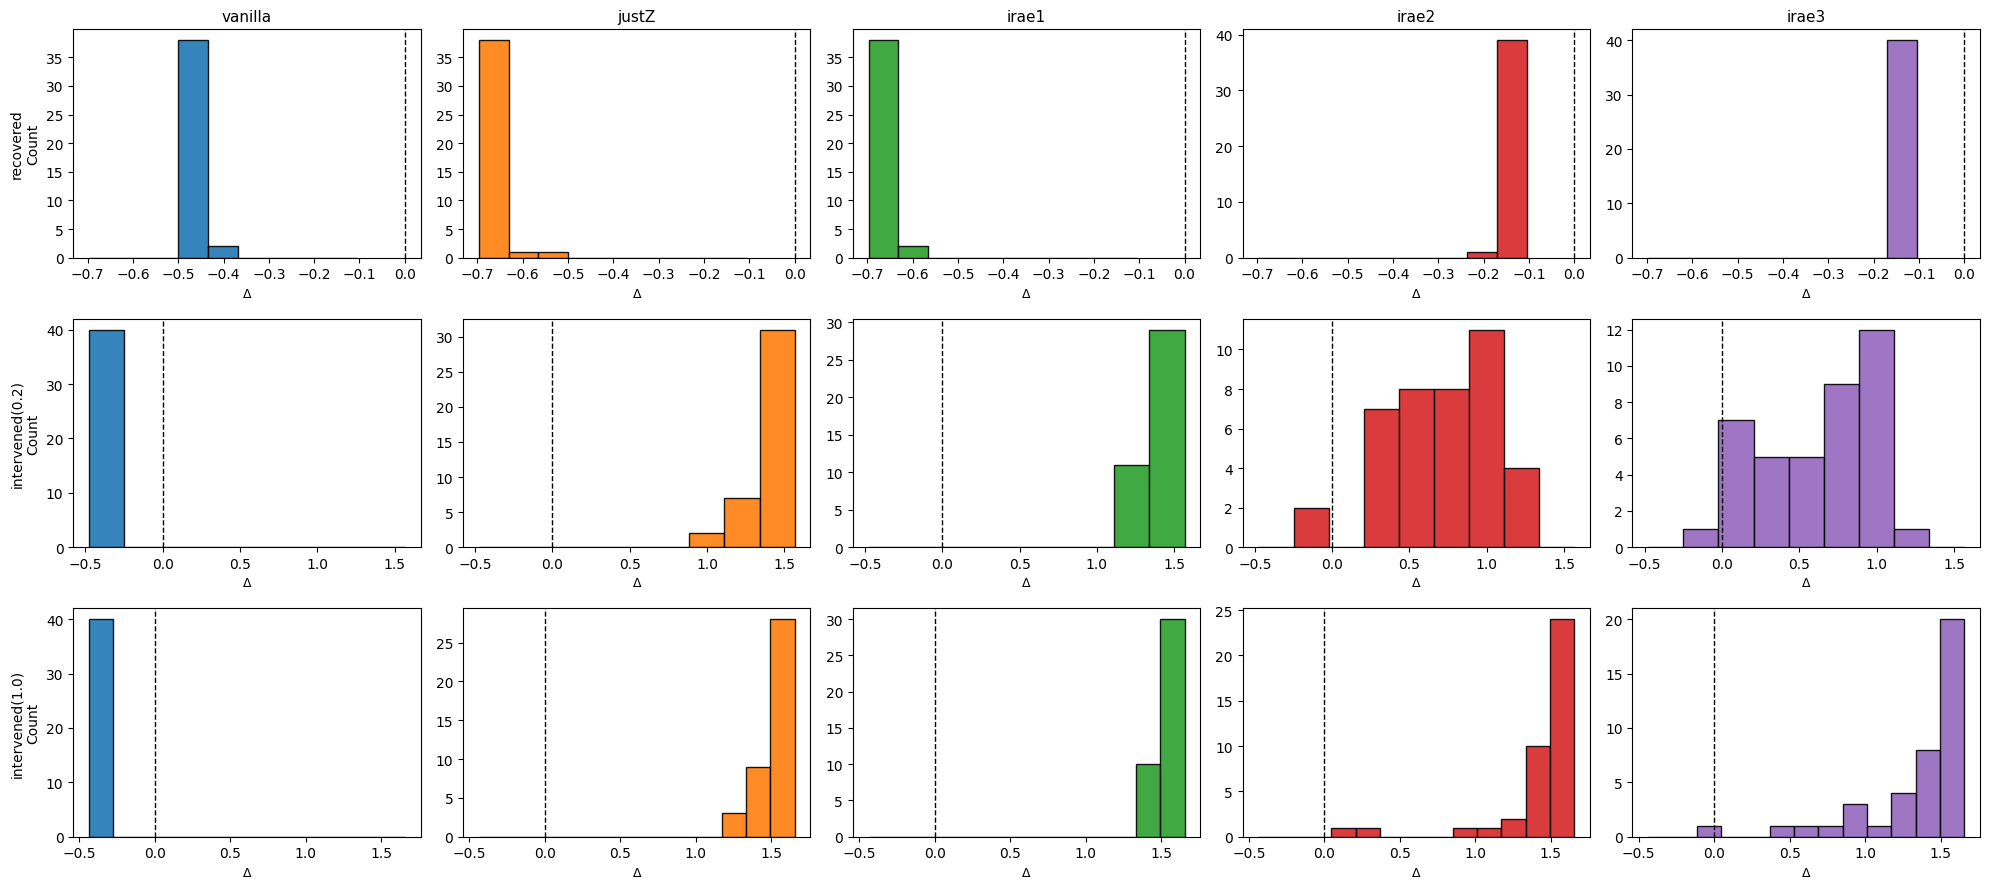

config_dgp2_dense_32_1.0_linear_hsic_50_256_5_True_50


true            original           recovered            \
             mean       std      mean       std      mean       std   
method                                                                
irae1    1.502673  0.002324  1.307258  0.002093  0.637556  0.018193   
irae2    1.502673  0.002324  1.307258  0.002093  1.051969  0.119968   
irae3    1.502673  0.002324  1.307258  0.002093  0.976082  0.250814   
justZ    1.502673  0.002324  1.307258  0.002093  0.637146  0.023963   
vanilla  1.502673  0.002324  1.307258  0.002093  0.843164  0.020536   

        intervened(0.2)           intervened(1.0)            
                   mean       std            mean       std  
method                                                       
irae1          2.704603  0.102484        2.846061  0.090137  
irae2          2.387447  0.358827        2.596166  0.416106  
irae3          2.103235  0.696999        2.353209  0.683294  
justZ          2.712072  0.117454        2.844415  0.113935  
vanilla        0.861240  0.017841        0.934845  0.025134

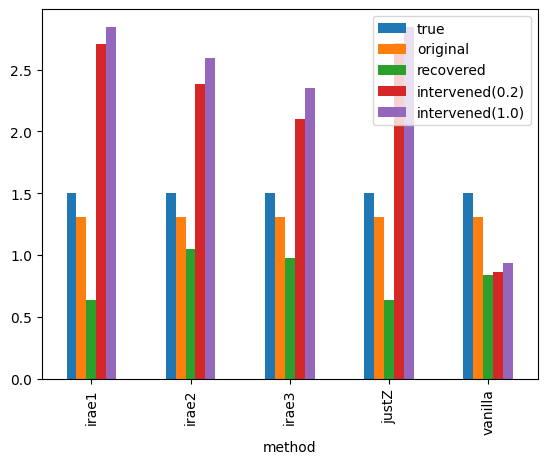

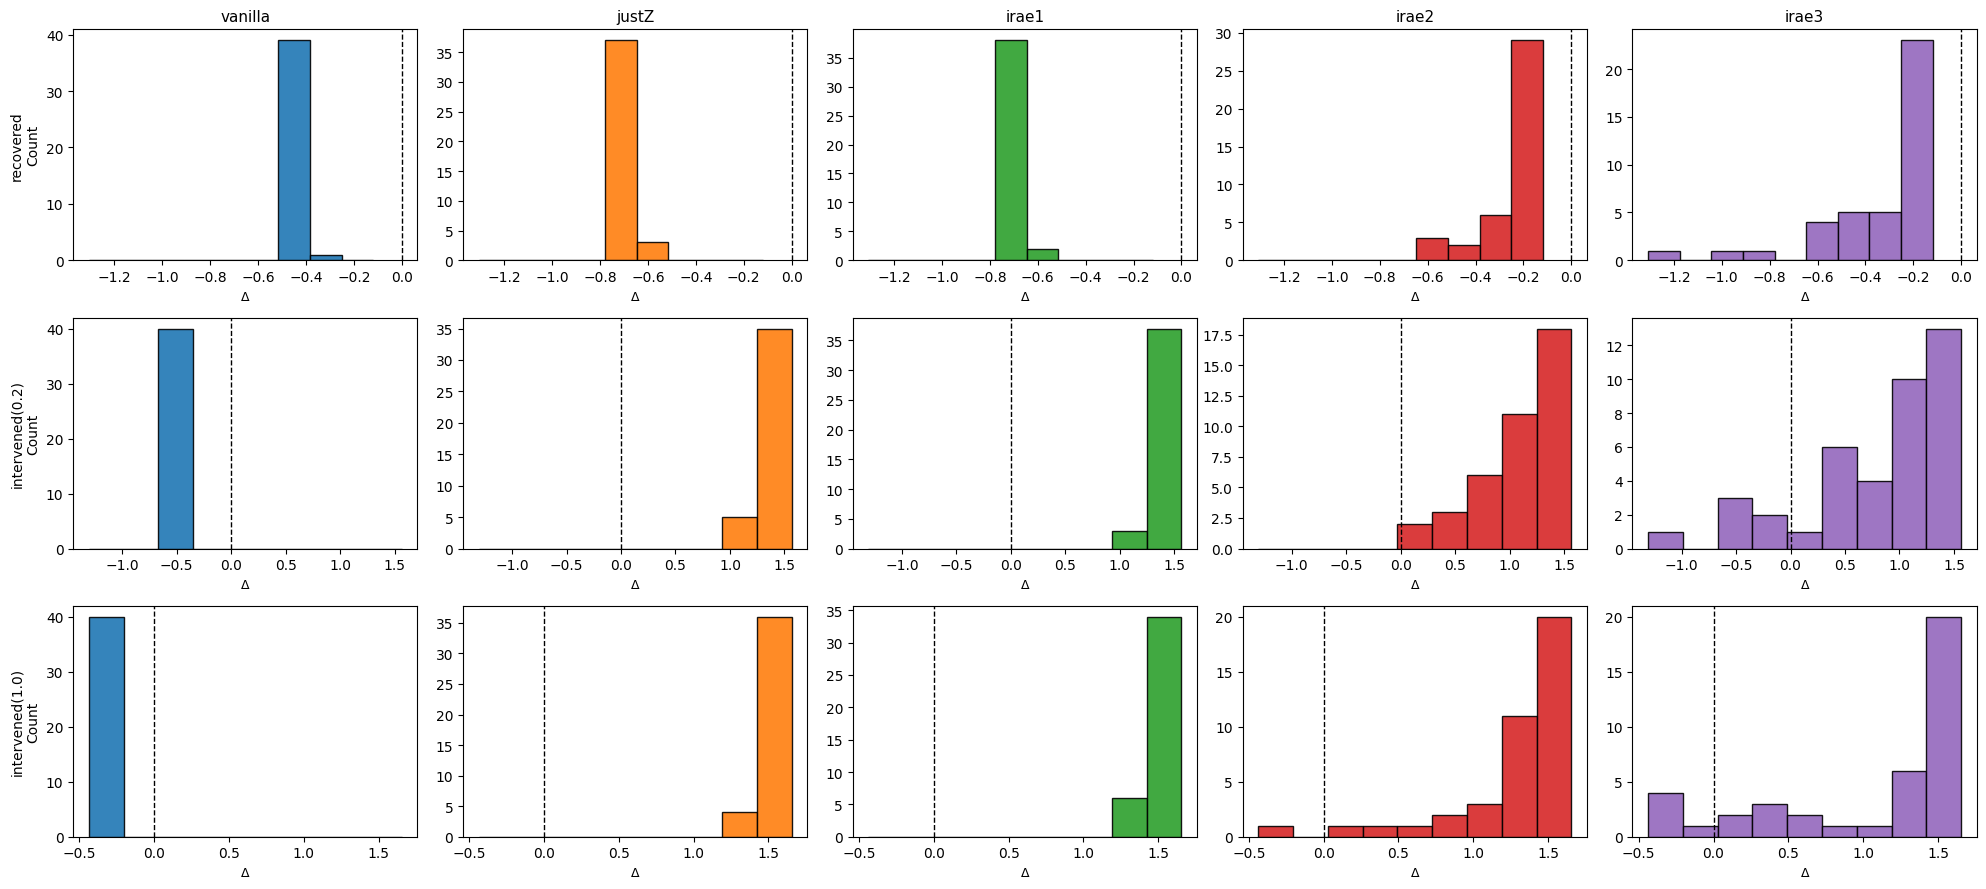

config_dgp2_dense_32_1.0_pairwise_hsic_50_256_5_False_50


true            original           recovered            \
             mean       std      mean       std      mean       std   
method                                                                
irae1    1.502673  0.002324  1.307258  0.002093  0.626096  0.014128   
irae2    1.502673  0.002324  1.307258  0.002093  1.173233  0.012324   
irae3    1.502673  0.002324  1.307258  0.002093  1.113440  0.017127   
justZ    1.502673  0.002324  1.307258  0.002093  0.637146  0.023963   
vanilla  1.502673  0.002324  1.307258  0.002093  0.843164  0.020536   

        intervened(0.2)           intervened(1.0)            
                   mean       std            mean       std  
method                                                       
irae1          2.709878  0.142581        2.840256  0.133995  
irae2          1.159921  0.050683        1.107236  0.177294  
irae3          1.094994  0.103993        1.085863  0.279629  
justZ          2.712072  0.117454        2.844415  0.113935  
vanilla        0.861240  0.017841        0.934845  0.025134

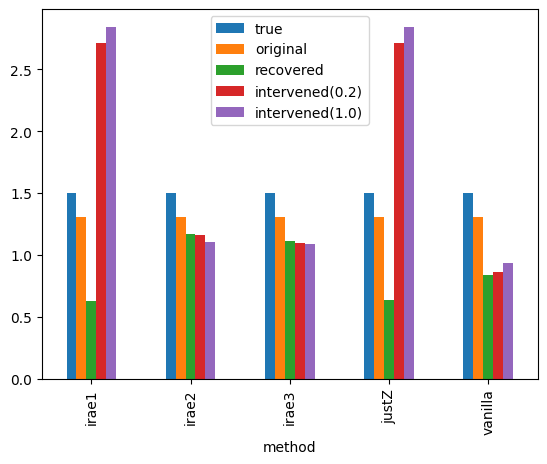

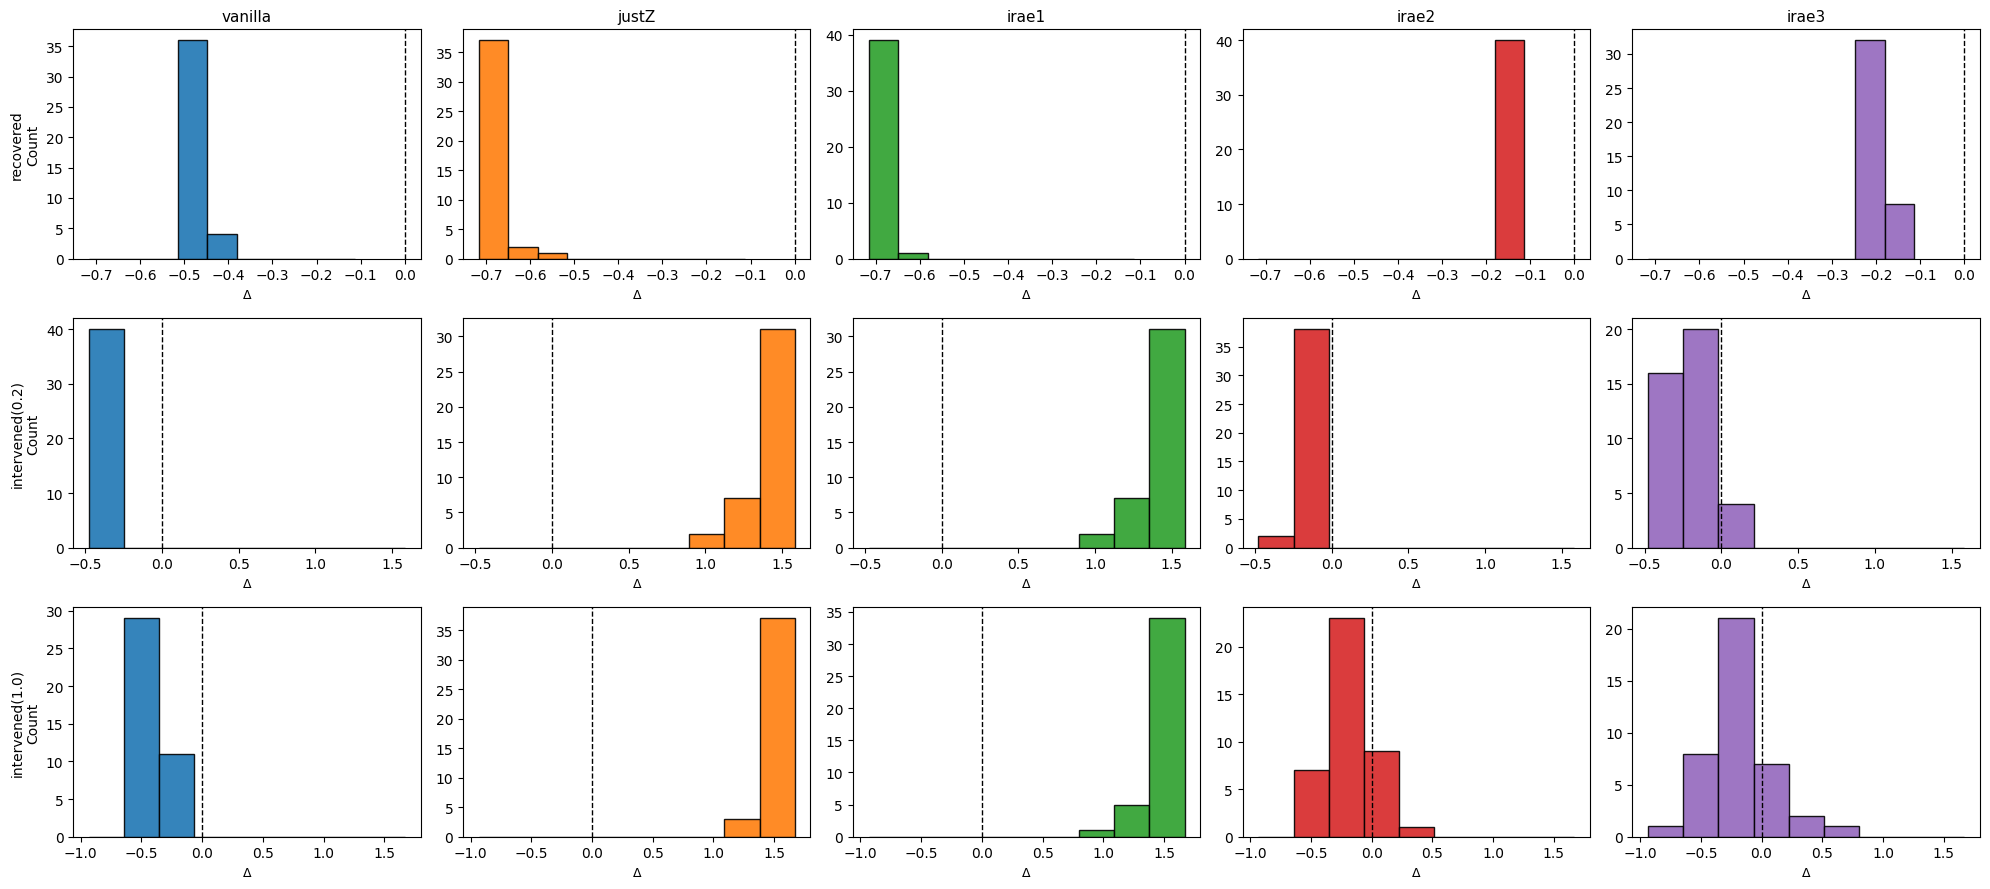

config_dgp2_dense_32_1.0_pairwise_hsic_50_256_5_True_50


true            original           recovered            \
             mean       std      mean       std      mean       std   
method                                                                
irae1    1.502673  0.002324  1.307258  0.002093  0.626096  0.014128   
irae2    1.502673  0.002324  1.307258  0.002093  1.113826  0.049936   
irae3    1.502673  0.002324  1.307258  0.002093  0.971014  0.202633   
justZ    1.502673  0.002324  1.307258  0.002093  0.637146  0.023963   
vanilla  1.502673  0.002324  1.307258  0.002093  0.843164  0.020536   

        intervened(0.2)           intervened(1.0)            
                   mean       std            mean       std  
method                                                       
irae1          2.709878  0.142581        2.840256  0.133995  
irae2          1.373673  0.414750        1.729179  0.646404  
irae3          1.440334  0.534376        1.803026  0.672321  
justZ          2.712072  0.117454        2.844415  0.113935  
vanilla        0.861240  0.017841        0.934845  0.025134

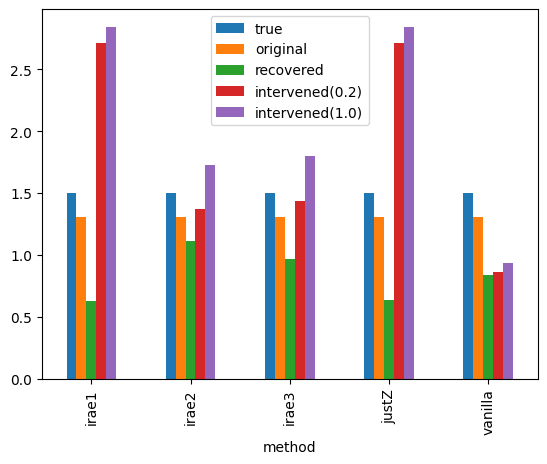

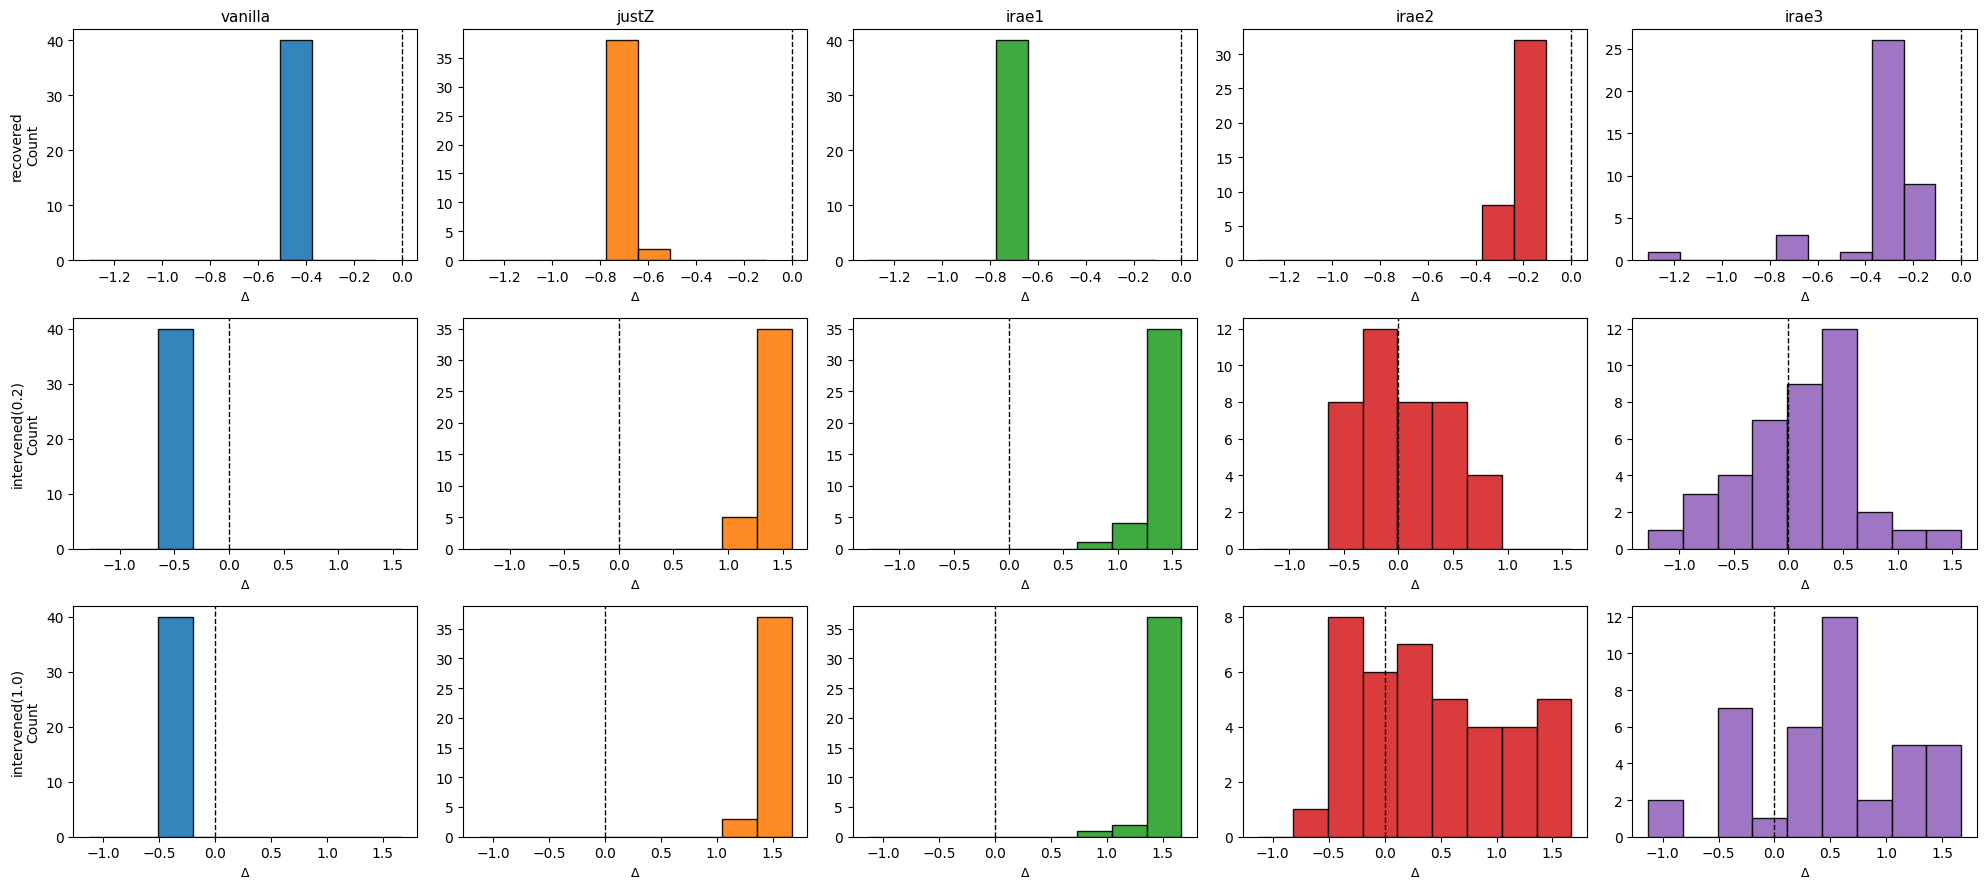

config_dgp2_conv_10_1.0_linear_hsic_50_256_5_False_50


true            original           recovered            \
             mean       std      mean       std      mean       std   
method                                                                
irae1    1.502673  0.002324  1.307258  0.002093  0.709213  0.047905   
irae2    1.502673  0.002324  1.307258  0.002093  1.099486  0.032182   
irae3    1.502673  0.002324  1.307258  0.002093  1.078826  0.027649   
justZ    1.502673  0.002324  1.307258  0.002093  0.712025  0.057991   
vanilla  1.502673  0.002324  1.307258  0.002093  0.933661  0.023952   

        intervened(0.2)           intervened(1.0)            
                   mean       std            mean       std  
method                                                       
irae1          1.704291  0.401939        2.002079  0.577188  
irae2          2.289876  0.229993        2.553600  0.548853  
irae3          2.104563  0.391298        2.430916  0.648231  
justZ          1.517013  0.342881        1.707261  0.560737  
vanilla        0.946352  0.033700        0.998342  0.074129

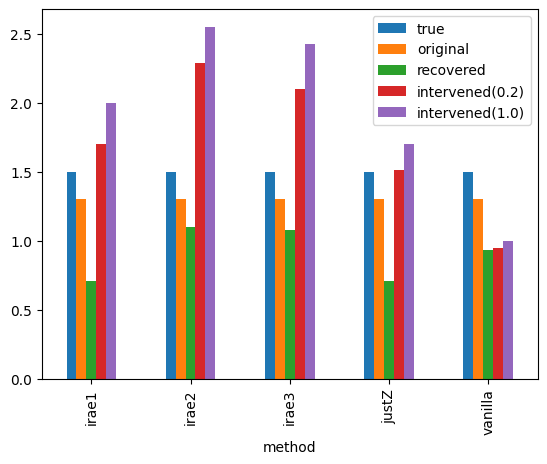

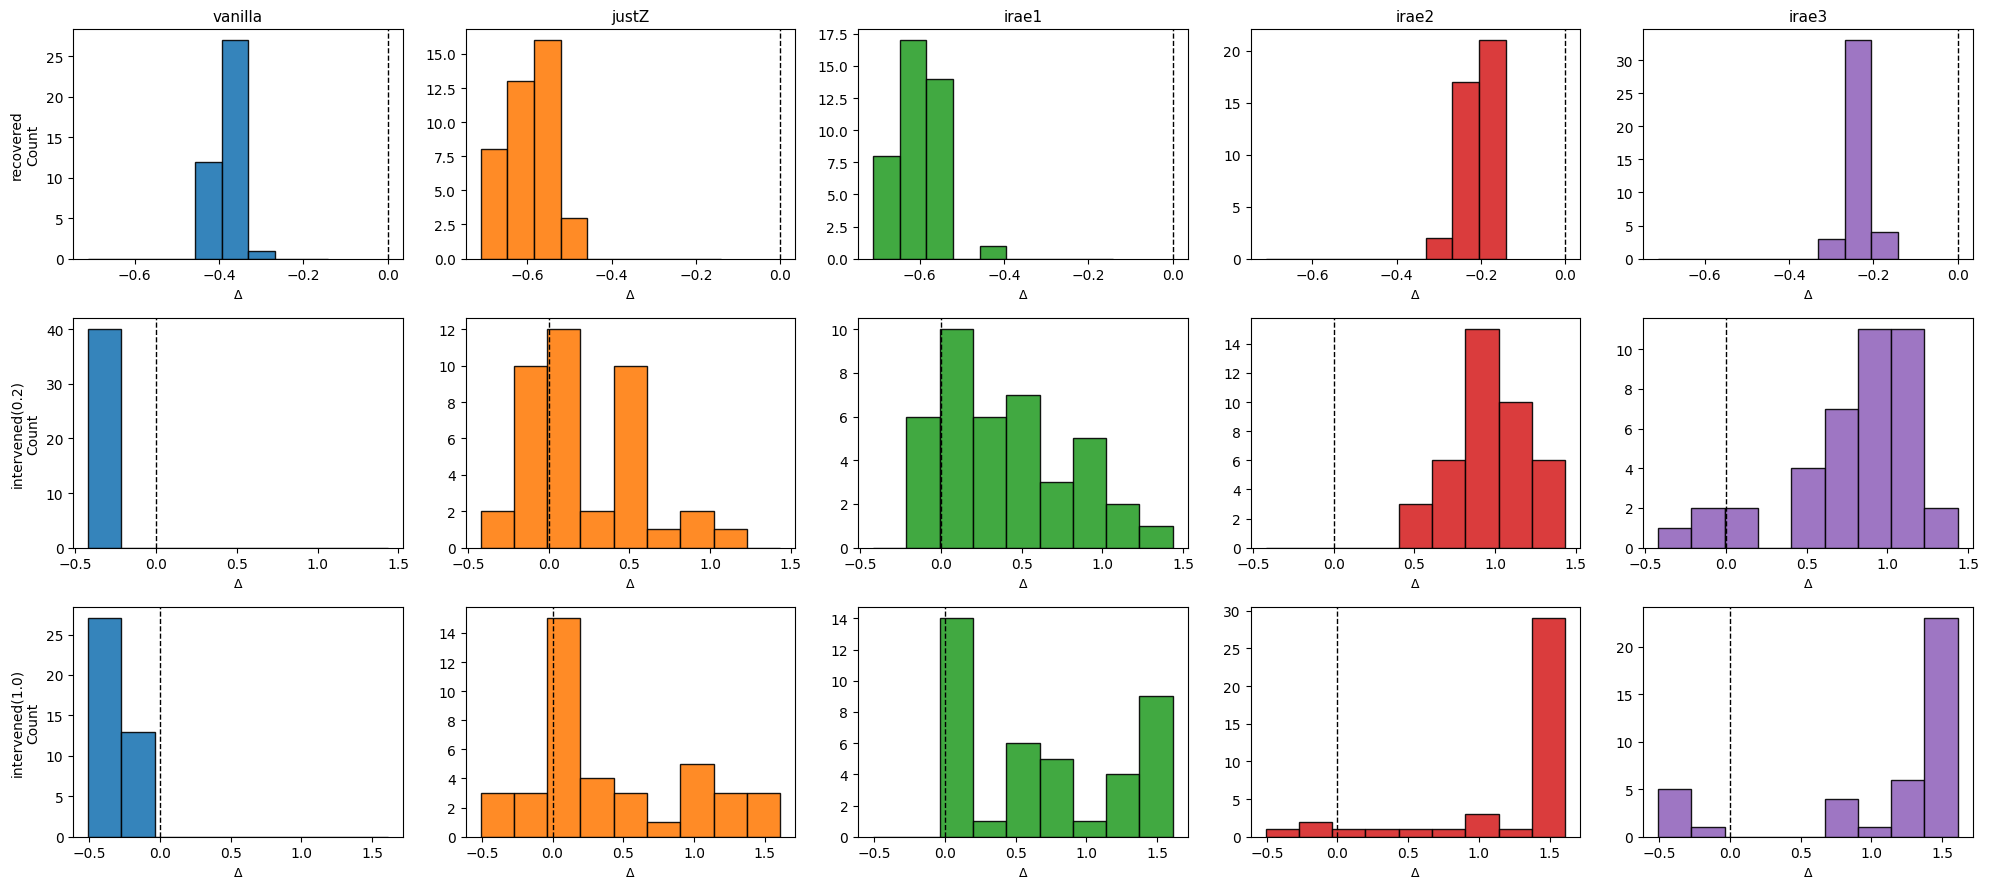

config_dgp2_conv_10_1.0_linear_hsic_50_256_5_True_50


true            original           recovered            \
             mean       std      mean       std      mean       std   
method                                                                
irae1    1.502673  0.002324  1.307258  0.002093  0.709213  0.047905   
irae2    1.502673  0.002324  1.307258  0.002093  1.104865  0.041223   
irae3    1.502673  0.002324  1.307258  0.002093  1.109167  0.037097   
justZ    1.502673  0.002324  1.307258  0.002093  0.712025  0.057991   
vanilla  1.502673  0.002324  1.307258  0.002093  0.933661  0.023952   

        intervened(0.2)           intervened(1.0)            
                   mean       std            mean       std  
method                                                       
irae1          1.704291  0.401939        2.002079  0.577188  
irae2          2.305898  0.450597        2.193825  0.747417  
irae3          2.205993  0.571453        2.041648  0.766799  
justZ          1.517013  0.342881        1.707261  0.560737  
vanilla        0.946352  0.033700        0.998342  0.074129

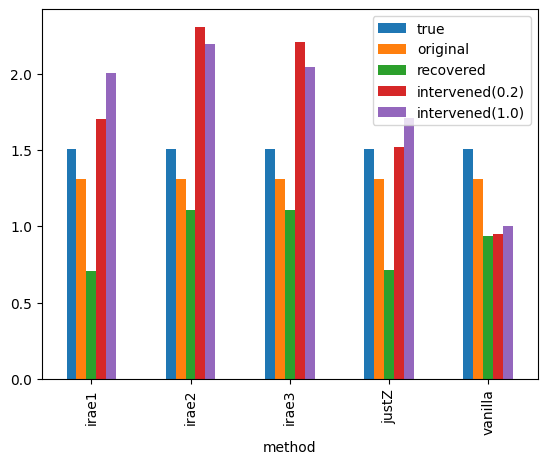

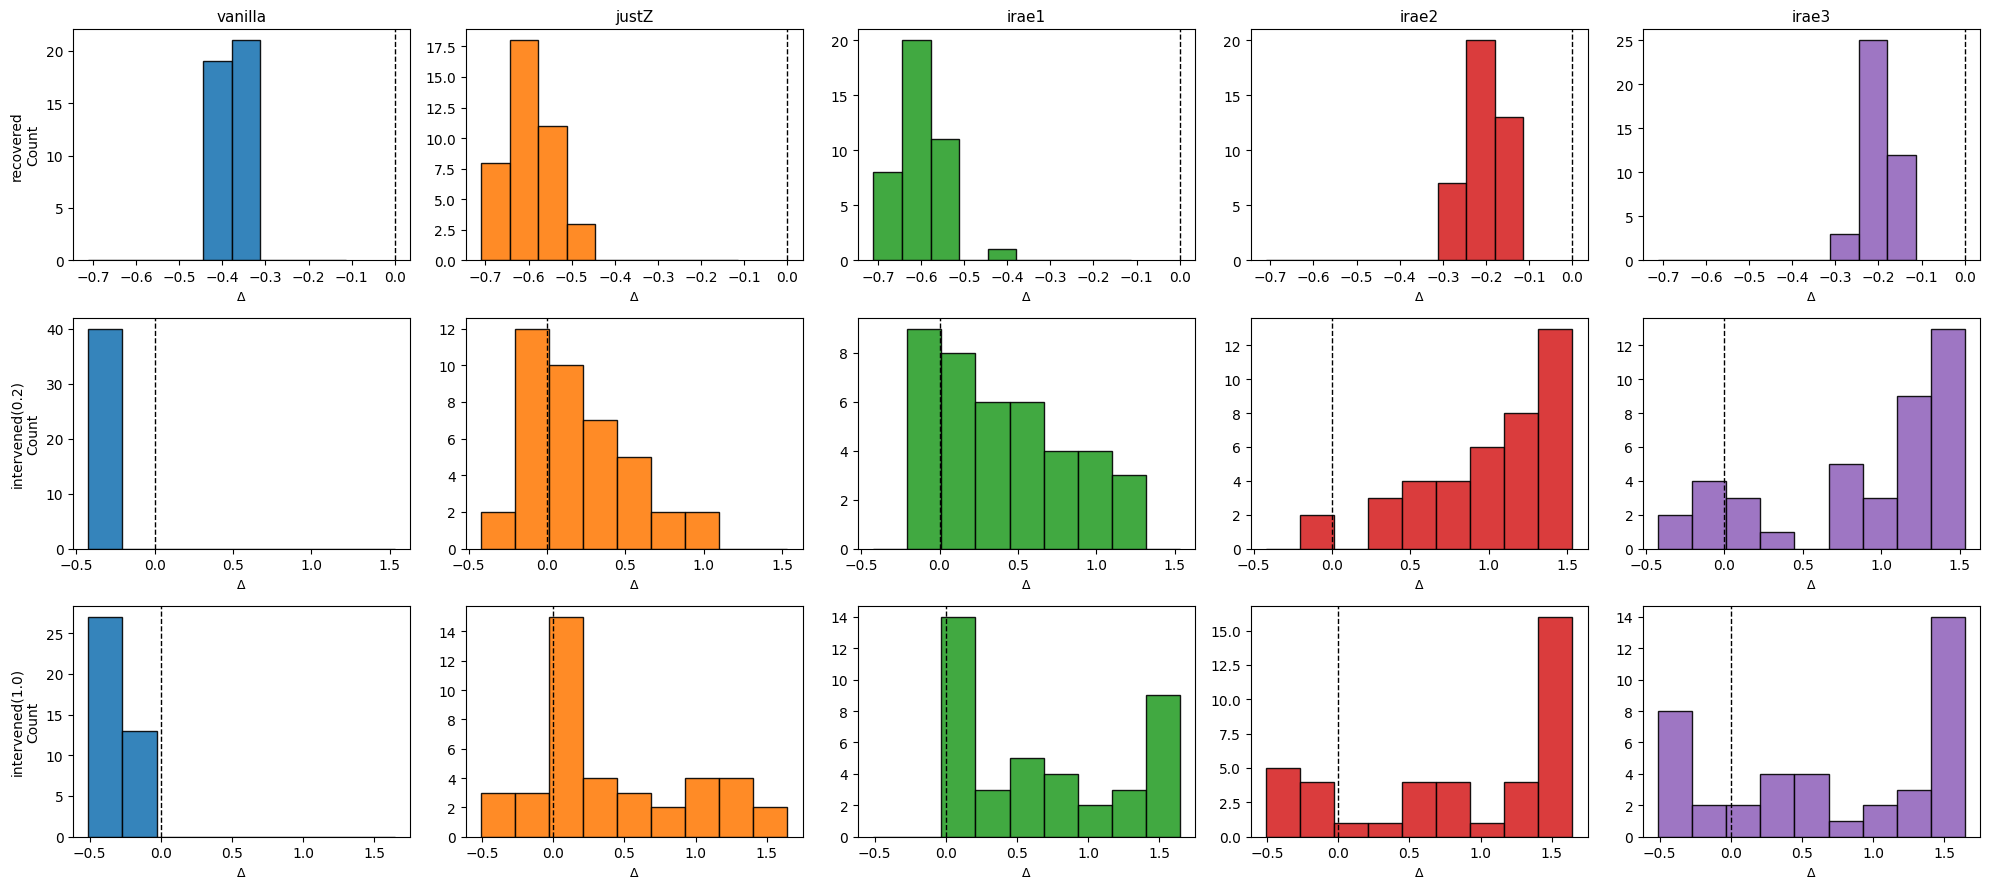

config_dgp2_conv_10_1.0_pairwise_hsic_50_256_5_False_50


true            original           recovered            \
             mean       std      mean       std      mean       std   
method                                                                
irae1    1.502673  0.002324  1.307258  0.002093  0.710058  0.052932   
irae2    1.502673  0.002324  1.307258  0.002093  1.087537  0.048353   
irae3    1.502673  0.002324  1.307258  0.002093  1.048948  0.058872   
justZ    1.502673  0.002324  1.307258  0.002093  0.712025  0.057991   
vanilla  1.502673  0.002324  1.307258  0.002093  0.933661  0.023952   

        intervened(0.2)           intervened(1.0)            
                   mean       std            mean       std  
method                                                       
irae1          1.349798  0.451112        1.432244  0.565907  
irae2          1.779129  0.422583        2.171228  0.469989  
irae3          1.753179  0.447949        2.104894  0.630683  
justZ          1.517013  0.342881        1.707261  0.560737  
vanilla        0.946352  0.033700        0.998342  0.074129

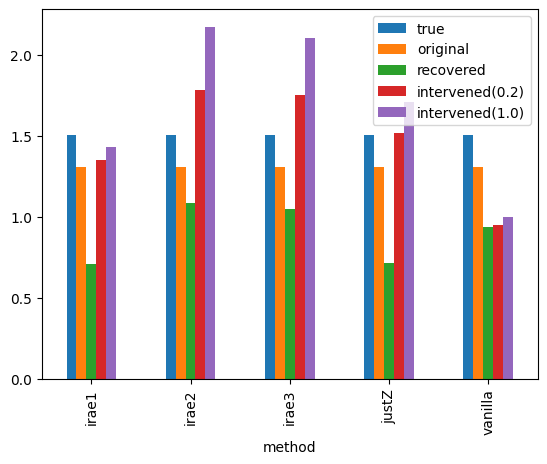

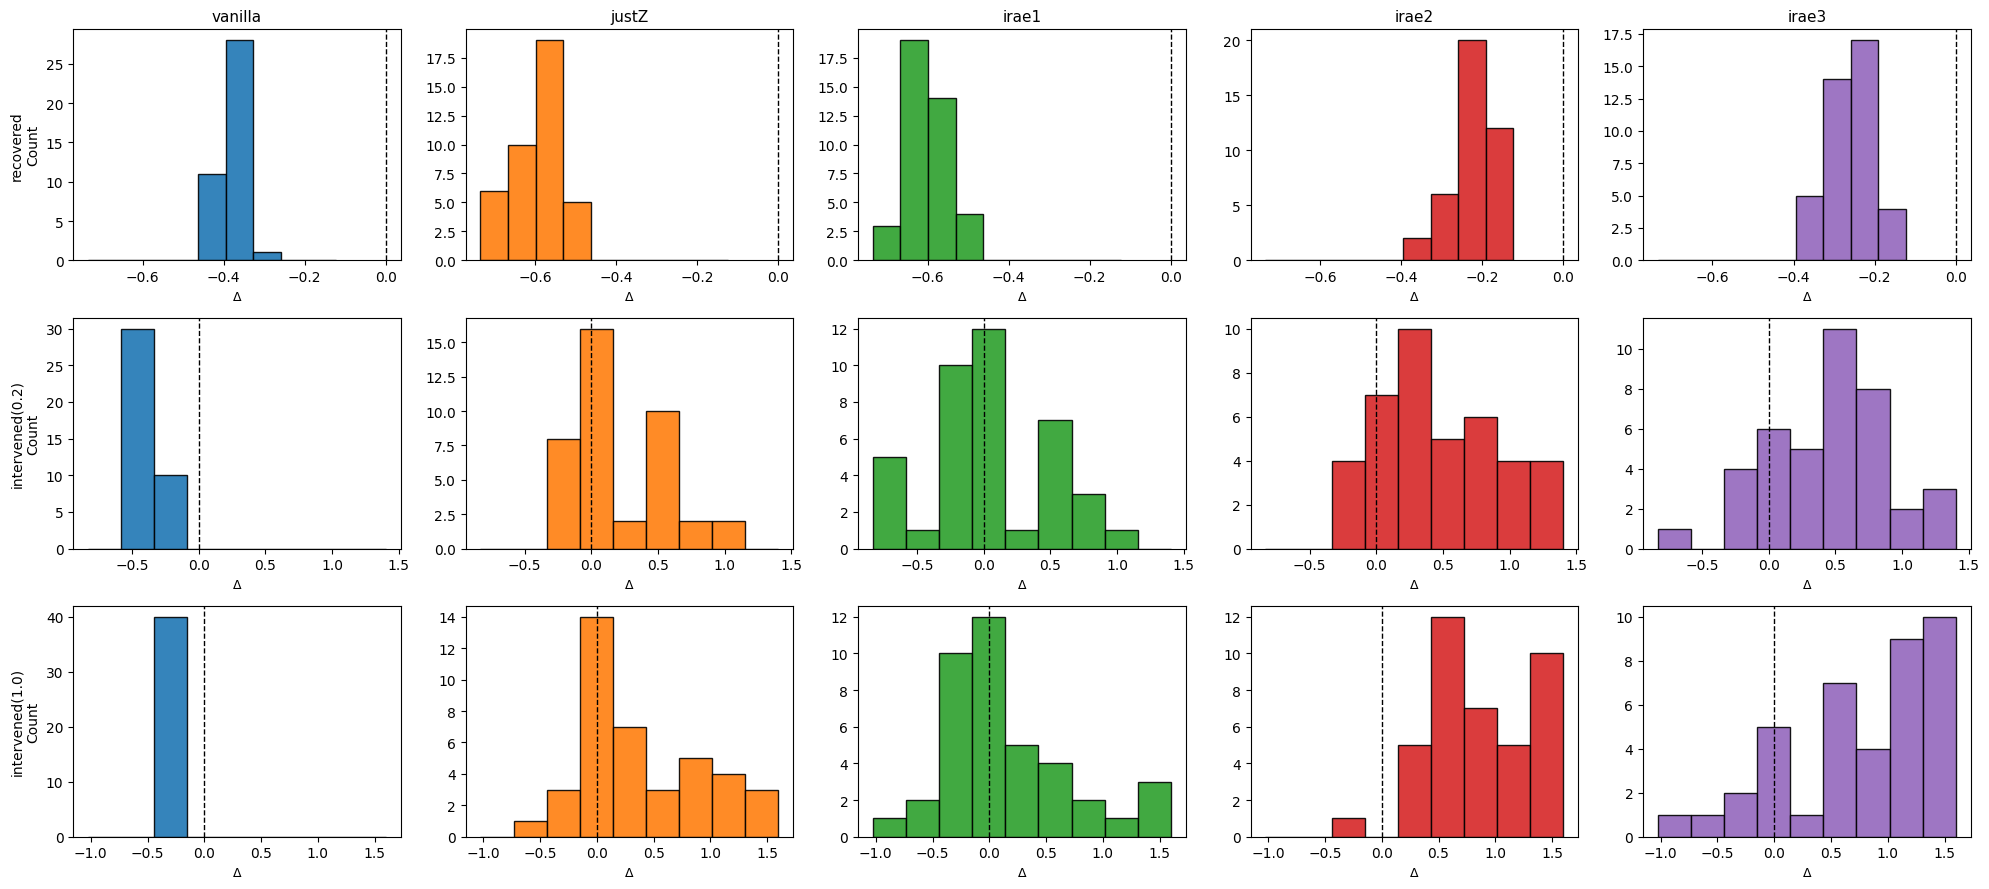

config_dgp2_conv_10_1.0_pairwise_hsic_50_256_5_True_50


true            original           recovered            \
             mean       std      mean       std      mean       std   
method                                                                
irae1    1.502673  0.002324  1.307258  0.002093  0.710058  0.052932   
irae2    1.502673  0.002324  1.307258  0.002093  1.043861  0.069117   
irae3    1.502673  0.002324  1.307258  0.002093  1.033036  0.097185   
justZ    1.502673  0.002324  1.307258  0.002093  0.712025  0.057991   
vanilla  1.502673  0.002324  1.307258  0.002093  0.933661  0.023952   

        intervened(0.2)           intervened(1.0)            
                   mean       std            mean       std  
method                                                       
irae1          1.349798  0.451112        1.432244  0.565907  
irae2          2.123398  0.474235        2.385218  0.550572  
irae3          2.003268  0.475940        2.210774  0.556676  
justZ          1.517013  0.342881        1.707261  0.560737  
vanilla        0.946352  0.033700        0.998342  0.074129

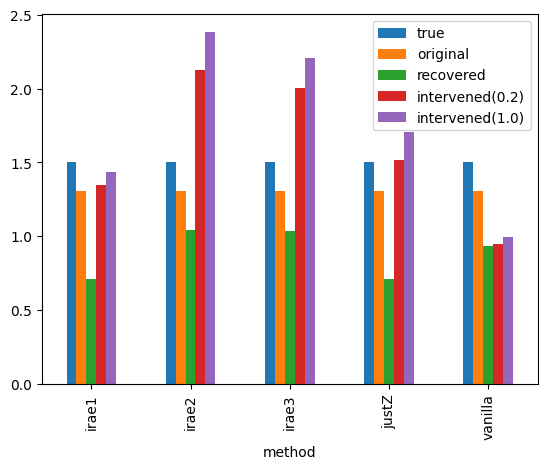

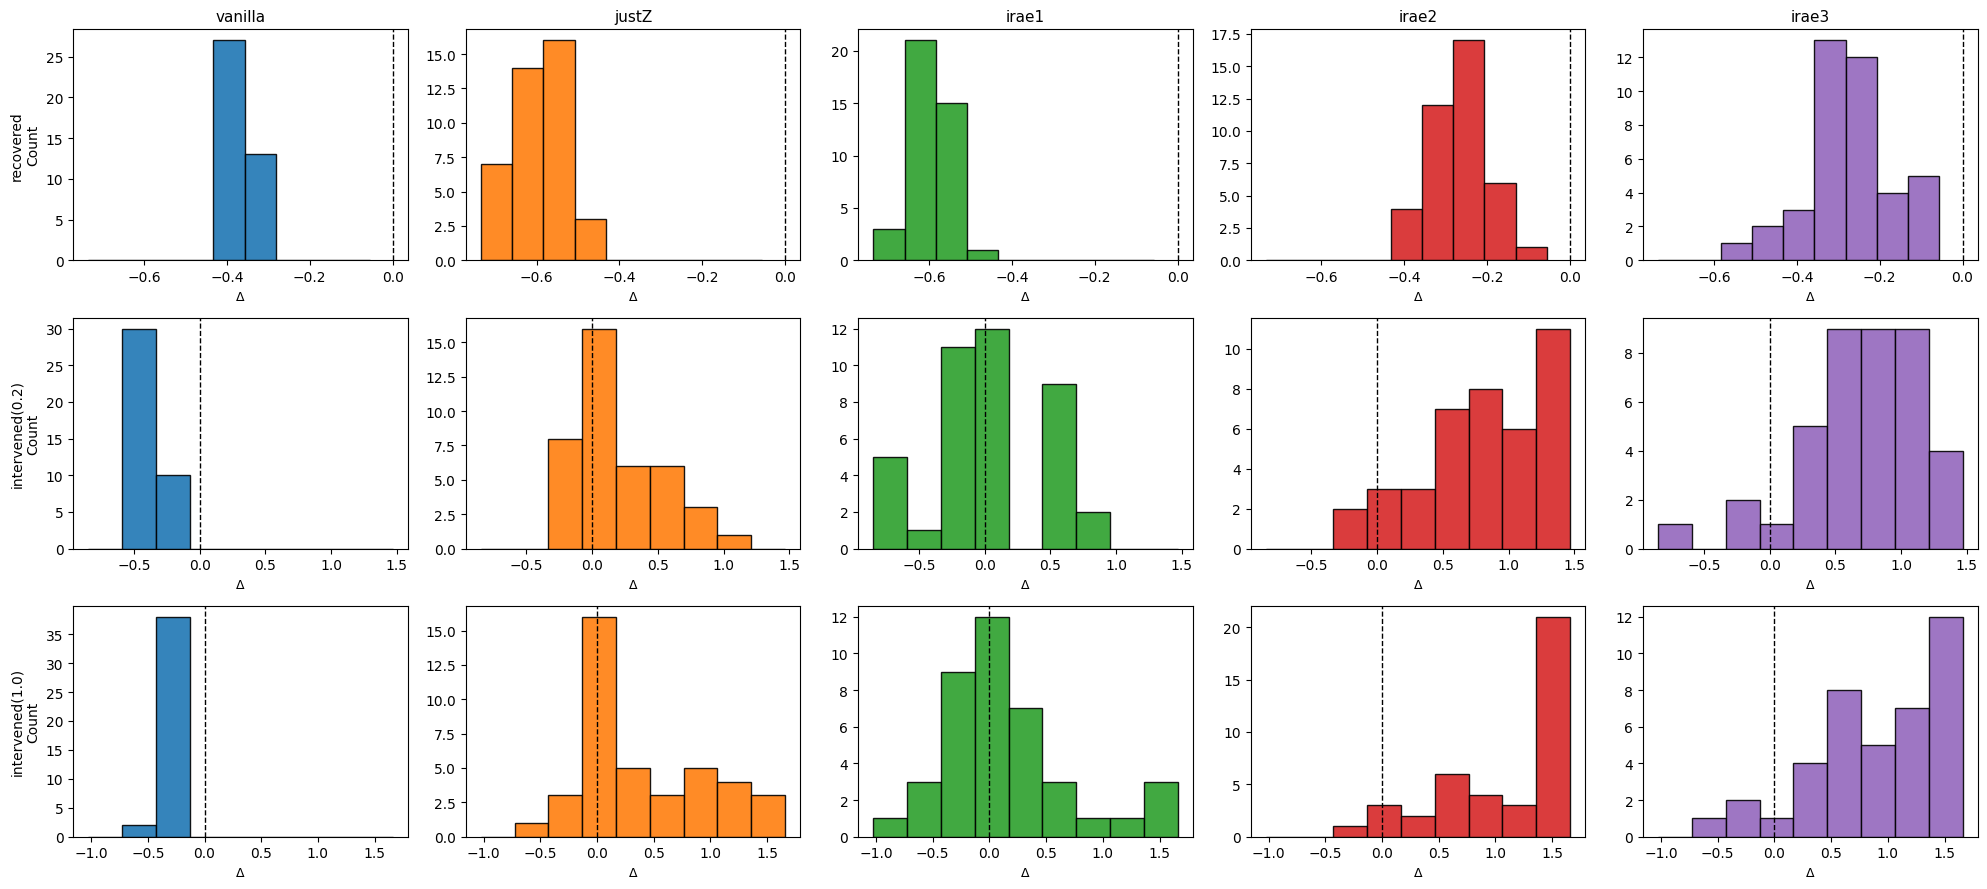

config_dgp2_conv_32_1.0_linear_hsic_50_256_5_False_50


true            original           recovered            \
             mean       std      mean       std      mean       std   
method                                                                
irae1    1.502673  0.002324  1.307258  0.002093  0.709213  0.047905   
irae2    1.502673  0.002324  1.307258  0.002093  1.205977  0.034775   
irae3    1.502673  0.002324  1.307258  0.002093  1.199525  0.029172   
justZ    1.502673  0.002324  1.307258  0.002093  0.712025  0.057991   
vanilla  1.502673  0.002324  1.307258  0.002093  0.933661  0.023952   

        intervened(0.2)           intervened(1.0)            
                   mean       std            mean       std  
method                                                       
irae1          1.704291  0.401939        2.002079  0.577188  
irae2          2.004595  0.333633        2.565404  0.389870  
irae3          1.926433  0.378872        2.349689  0.522913  
justZ          1.517013  0.342881        1.707261  0.560737  
vanilla        0.946352  0.033700        0.998342  0.074129

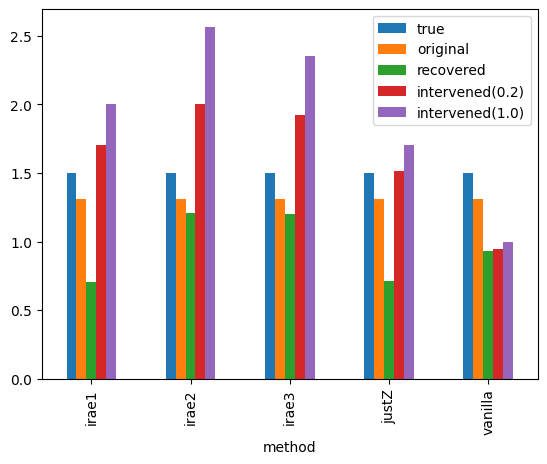

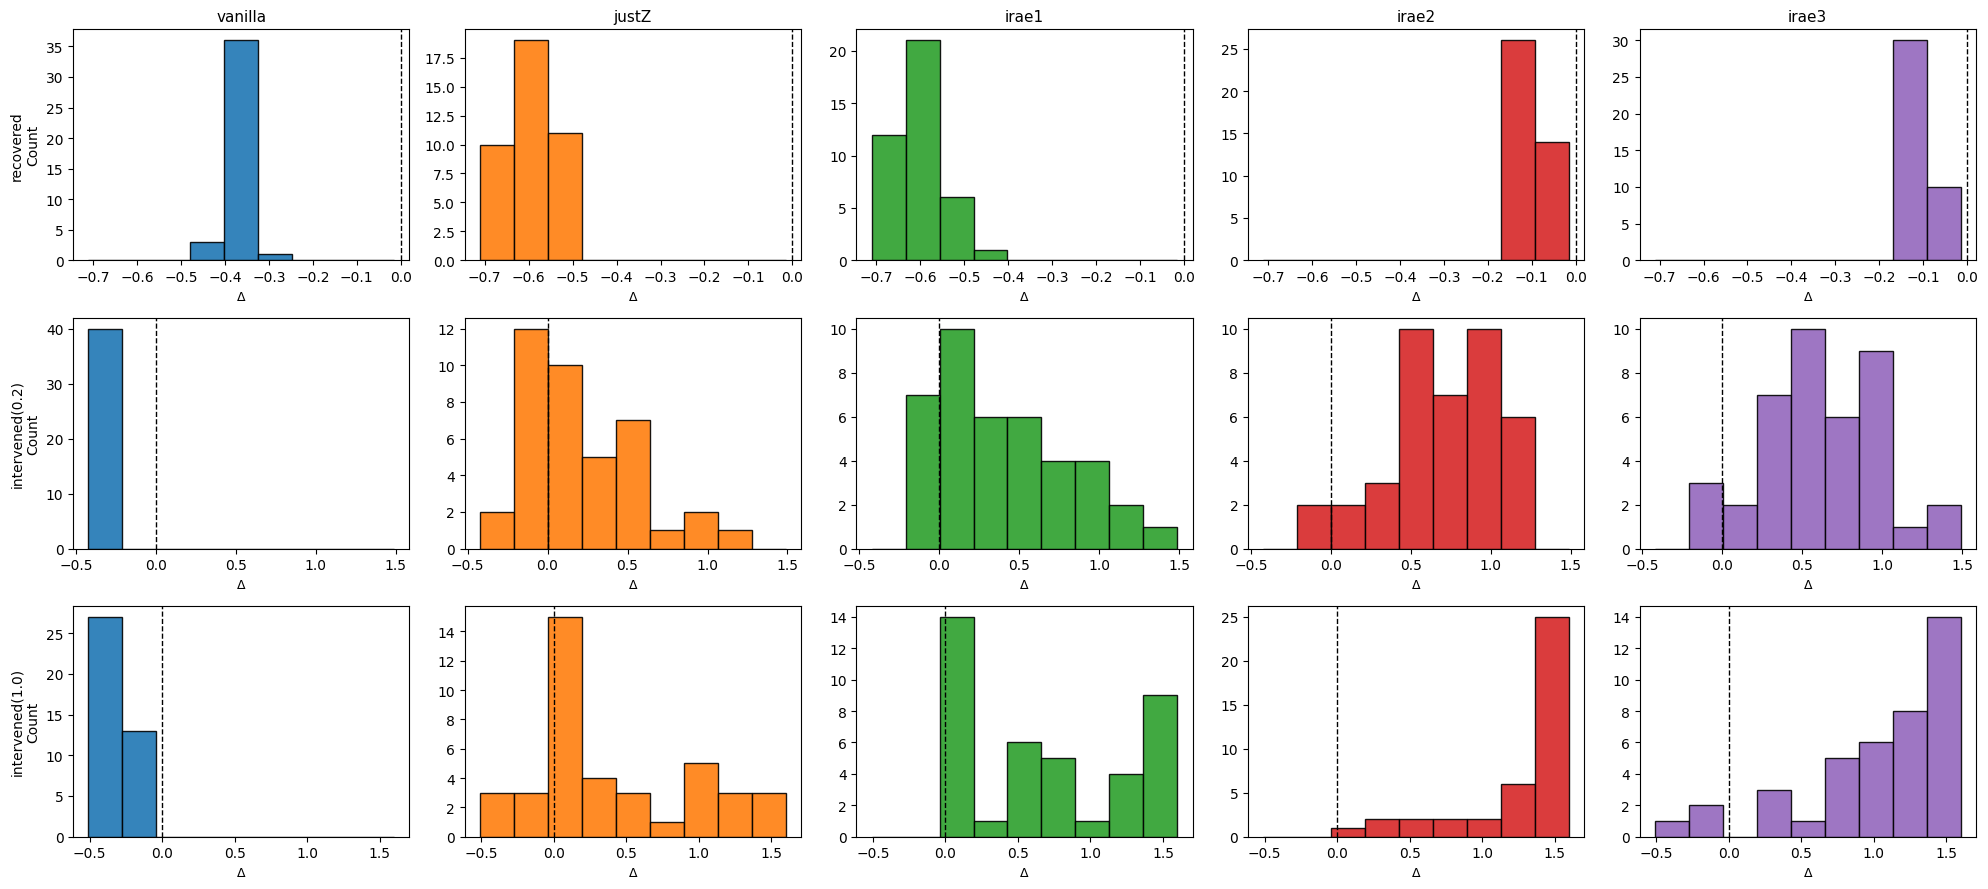

config_dgp2_conv_32_1.0_linear_hsic_50_256_5_True_50


true            original           recovered            \
             mean       std      mean       std      mean       std   
method                                                                
irae1    1.502673  0.002324  1.307258  0.002093  0.709213  0.047905   
irae2    1.502673  0.002324  1.307258  0.002093  1.203701  0.031400   
irae3    1.502673  0.002324  1.307258  0.002093  1.208847  0.023209   
justZ    1.502673  0.002324  1.307258  0.002093  0.712025  0.057991   
vanilla  1.502673  0.002324  1.307258  0.002093  0.933661  0.023952   

        intervened(0.2)           intervened(1.0)            
                   mean       std            mean       std  
method                                                       
irae1          1.704291  0.401939        2.002079  0.577188  
irae2          2.361377  0.485882        2.412380  0.574199  
irae3          2.452735  0.507449        2.529390  0.598353  
justZ          1.517013  0.342881        1.707261  0.560737  
vanilla        0.946352  0.033700        0.998342  0.074129

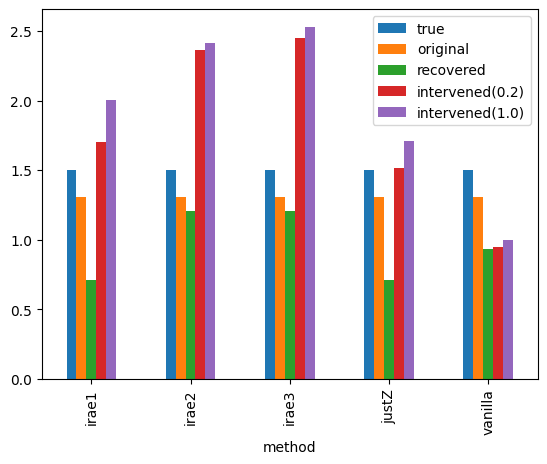

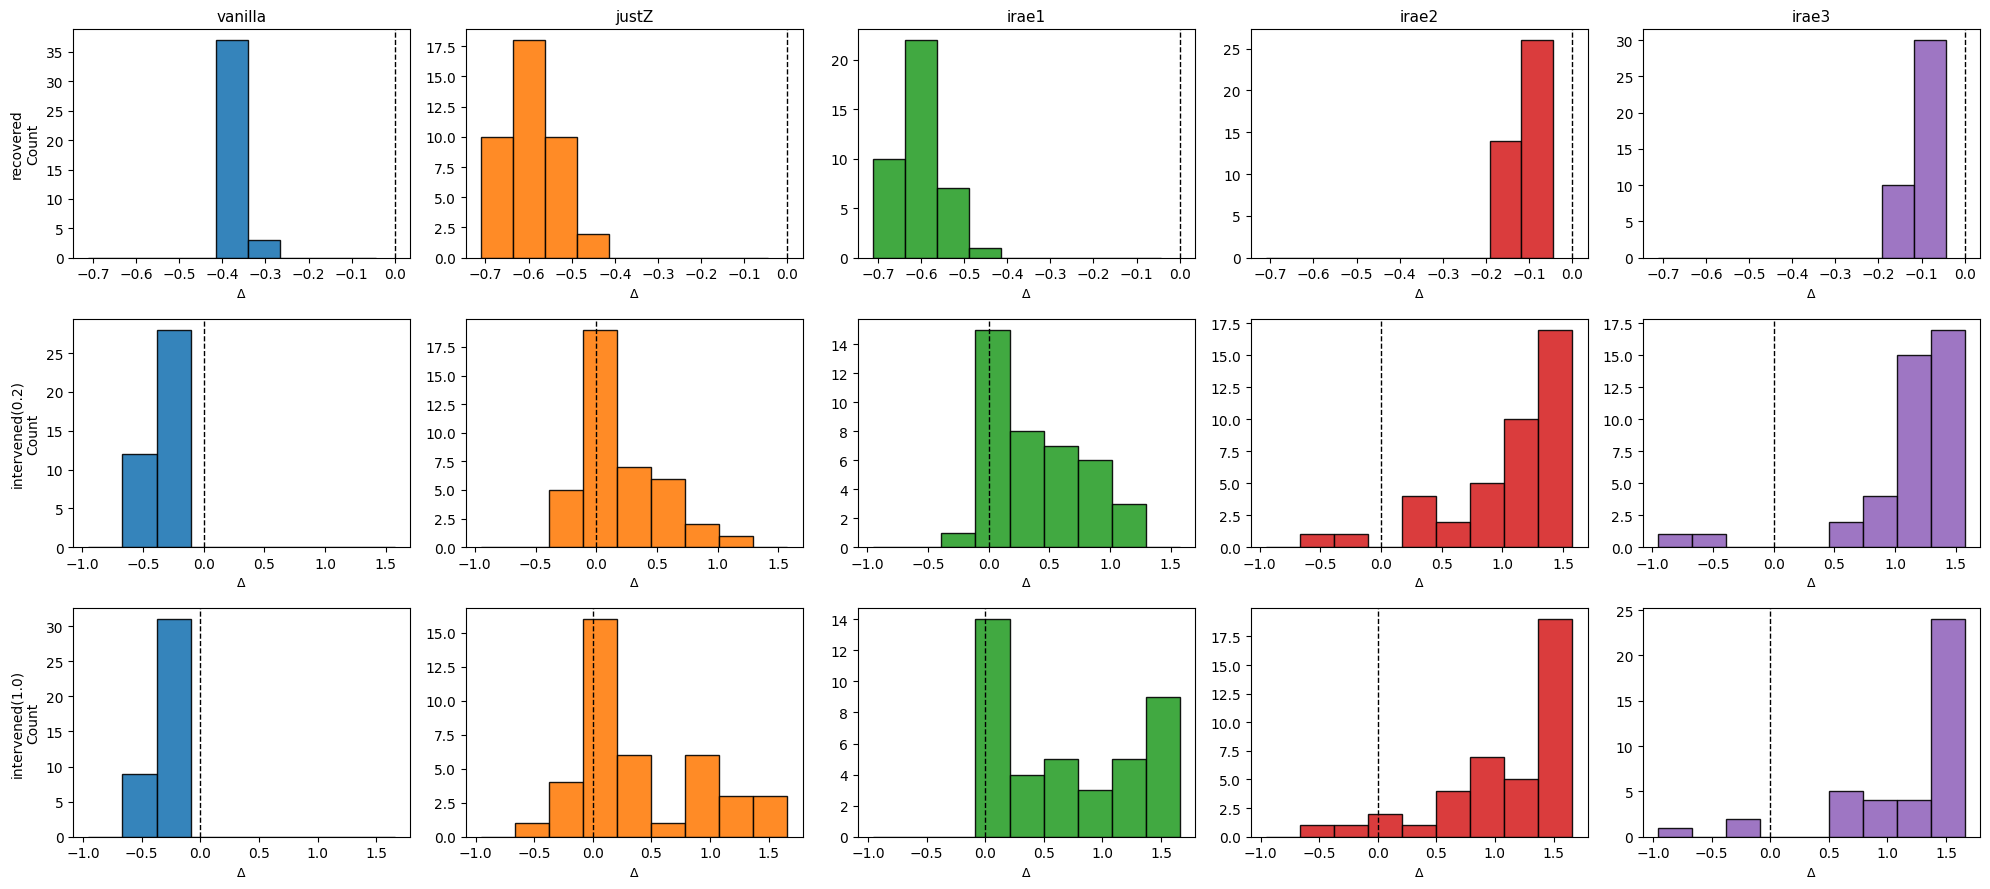

config_dgp2_conv_32_1.0_pairwise_hsic_50_256_5_False_50


true            original           recovered            \
             mean       std      mean       std      mean       std   
method                                                                
irae1    1.502673  0.002324  1.307258  0.002093  0.710058  0.052932   
irae2    1.502673  0.002324  1.307258  0.002093  1.199557  0.032926   
irae3    1.502673  0.002324  1.307258  0.002093  1.178250  0.048264   
justZ    1.502673  0.002324  1.307258  0.002093  0.712025  0.057991   
vanilla  1.502673  0.002324  1.307258  0.002093  0.933661  0.023952   

        intervened(0.2)           intervened(1.0)            
                   mean       std            mean       std  
method                                                       
irae1          1.349798  0.451112        1.432244  0.565907  
irae2          1.327365  0.263180        1.515424  0.493209  
irae3          1.433130  0.281168        1.655566  0.543363  
justZ          1.517013  0.342881        1.707261  0.560737  
vanilla        0.946352  0.033700        0.998342  0.074129

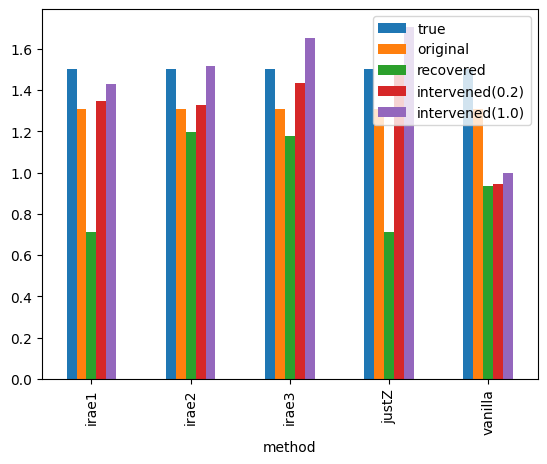

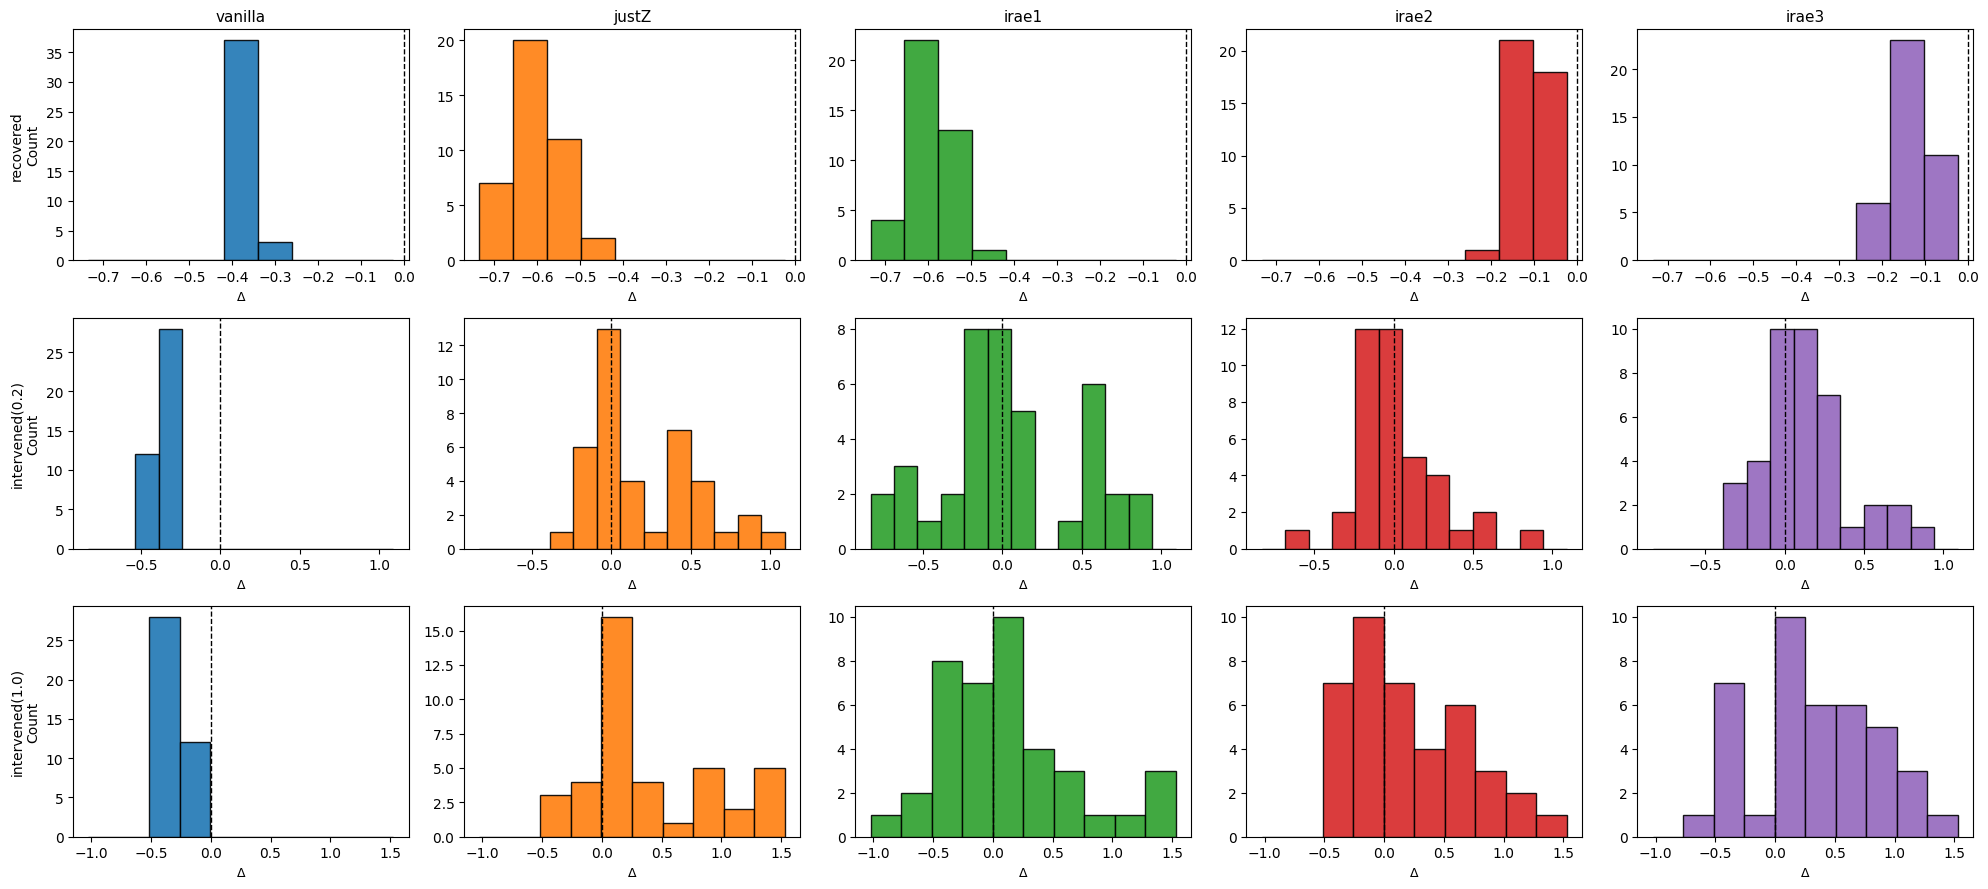

config_dgp2_conv_32_1.0_pairwise_hsic_50_256_5_True_50


true            original           recovered            \
             mean       std      mean       std      mean       std   
method                                                                
irae1    1.502673  0.002324  1.307258  0.002093  0.710058  0.052932   
irae2    1.502673  0.002324  1.307258  0.002093  1.168998  0.084358   
irae3    1.502673  0.002324  1.307258  0.002093  1.126137  0.082544   
justZ    1.502673  0.002324  1.307258  0.002093  0.712025  0.057991   
vanilla  1.502673  0.002324  1.307258  0.002093  0.933661  0.023952   

        intervened(0.2)           intervened(1.0)            
                   mean       std            mean       std  
method                                                       
irae1          1.349798  0.451112        1.432244  0.565907  
irae2          1.707209  0.558392        1.984844  0.679093  
irae3          1.659249  0.656932        2.011928  0.733773  
justZ          1.517013  0.342881        1.707261  0.560737  
vanilla        0.946352  0.033700        0.998342  0.074129

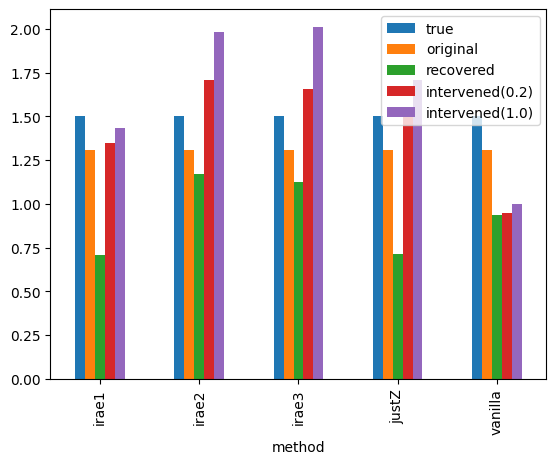

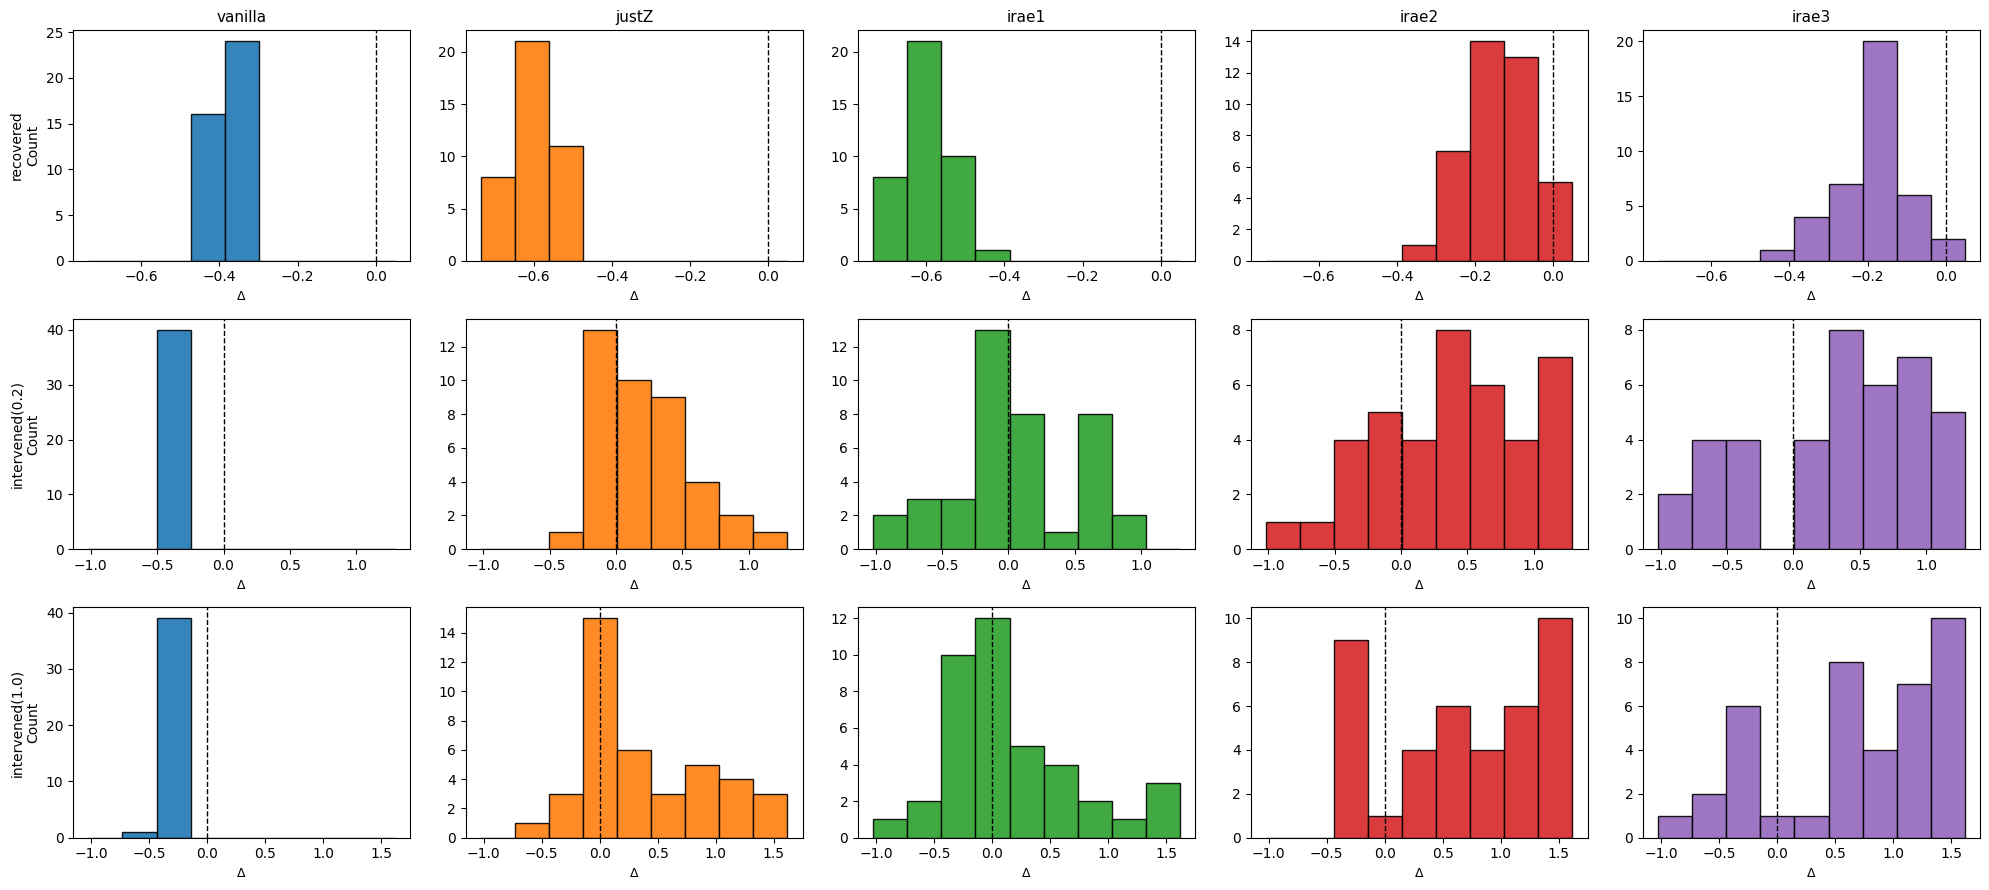

In [16]:
start = 0
finish = 39
dgp = 'dgp2'
archs = ['dense', 'conv']
ldims = [10, 32]
regweights = [1.0]
iregs = ['linear', 'pairwise']
trparams = [(50, 50, -1, 256, 5)]
warmstarts = [False, True]
get_reports(start, finish, dgp, archs, ldims, regweights, iregs, trparams, warmstarts)